In [1]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import matplotlib.pyplot as plt
from pycocotools.coco import COCO
import statsmodels.api as sm
import scipy.stats as stats
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import pandas as pd
from collections import Counter
import numpy as np

import matplotlib.pyplot as plt

from compcats.datasets.fmri import nsd
from compcats.utils import model_utils, seed_utils
from compcats.datasets.fmri.utils import nsd_ds_utils

import main_analysis as ma
import paths

# Set seed
SEED = 42
seed_utils.seed_everything(SEED)

# Directories
RESULTS_DIR = 'results'
os.makedirs(RESULTS_DIR, exist_ok=True)
MODELS_DIR = 'models'
os.makedirs(MODELS_DIR, exist_ok=True)

# Variables
batch_size = 2048
frois = ['FFA', 'PPA', 'EBA']
train_subjects = [1, 2, 5, 7]
test_subjects = [1, 2, 3, 4, 5, 6, 7, 8]
localizer = 'grillspector'
tthreshold = 7
test_model_name = 'resnet50imagenet1kv2'
train_model_name = 'resnet50openaiclip'

# COCO
coco_animal_labels = ['bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe']
coco_face_labels = coco_animal_labels + ['person']
coco_train = COCO(paths.COCO_TRAIN_ANNOTATIONS_PATH)
coco_val = COCO(paths.COCO_VAL_ANNOTATIONS_PATH)

loading annotations into memory...
Done (t=7.74s)
creating index...
index created!
loading annotations into memory...
Done (t=0.34s)
creating index...
index created!


In [2]:
# Util functions
def get_image_labels(image_id, coco_obj):
    """
    Get the labels for an image given its ID from the COCO dataset.
    
    Args:
        image_id (int): The ID of the image.
        
    Returns:
        list: A list of labels (category names) associated with the image.
    """
    # Get all annotations for the given image
    annotation_ids = coco_obj.getAnnIds(imgIds=image_id)
    annotations = coco_obj.loadAnns(annotation_ids)
    
    # Get category IDs from annotations
    category_ids = {annotation['category_id'] for annotation in annotations}
    
    # Get category names from category IDs
    category_names = [coco_obj.loadCats(cat_id)[0]['name'] for cat_id in category_ids]
    
    return category_names

def add_image_labels_to_df(df):
    """
    Add labels to the DataFrame given the COCO object.
    
    Args:
        df (pd.DataFrame): The DataFrame to which to add the labels.
        
    Returns:
        pd.DataFrame: The DataFrame with the labels added.
    """
    # Create a copy of the dataframe to avoid the SettingWithCopyWarning
    df_copy = df.copy()
    
    # Create a function to get the appropriate COCO object based on the split
    def get_coco_obj(split):
        if split == 'train2017':
            return coco_train
        else:
            return coco_val
        
    # Apply the function to get labels for each row using the appropriate COCO object
    df_copy.loc[:, 'labels'] = df_copy.apply(
        lambda row: get_image_labels(row['cocoId'], get_coco_obj(row['cocoSplit'])), 
        axis=1
    )
    return df_copy

def min_max_normalize(array):
    """
    Normalize the input array using min-max normalization.

    Parameters:
    array (numpy.ndarray or torch.Tensor): The input array to normalize.

    Returns:
    numpy.ndarray or torch.Tensor: The normalized array.
    """
    min_val = array.min()
    max_val = array.max()
    normalized_array = (array - min_val) / (max_val - min_val)
    return normalized_array

def z_score_normalize(array):
    """
    Normalize the input array using z-score normalization.

    Parameters:
    array (numpy.ndarray or torch.Tensor): The input array to normalize.

    Returns:
    numpy.ndarray or torch.Tensor: The normalized array.
    """
    mean_val = array.mean()
    std_val = array.std()
    normalized_array = (array - mean_val) / std_val
    return normalized_array

# FFA: NSD10k

In [3]:
froi = 'FFA'

model = ma.get_model(test_model_name)
all_models_layer = ma.get_froi_models_layers(froi, froi)
layer = all_models_layer[test_model_name]

model_allnsdstim_activations = model_utils.get_dataset_activations(
    MODELS_DIR, paths.NSD_DIR, model, layer, dataset='nsd', froi=froi, tthreshold=tthreshold, \
    froi_localizer=localizer, froi_localizer_dir=ma.get_localizer_dir(localizer), \
    batch_size=batch_size, device='cpu'
)

# All Stimuli
allstim, _ = nsd.get_subset_stimuli(paths.NSD_DIR)

In [75]:
# All Stimuli
allstim, _ = nsd.get_subset_stimuli(paths.NSD_DIR)

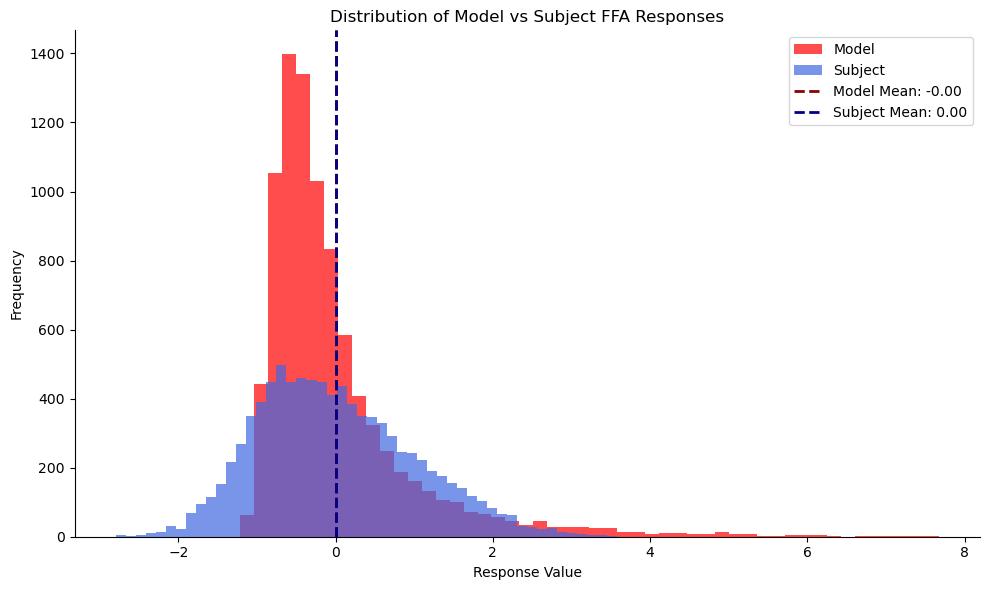

In [147]:
plt.figure(figsize=(10, 6))

# Plot histograms for both distributions
plt.hist(X, bins=50, alpha=0.7, color='red', label='Model')
plt.hist(y, bins=50, alpha=0.7, color='royalblue', label='Subject')

# Add mean lines
plt.axvline(X.mean(), color='darkred', linestyle='--', 
            linewidth=2, label=f'Model Mean: {X.mean():.2f}')
plt.axvline(y.mean(), color='darkblue', linestyle='--', 
            linewidth=2, label=f'Subject Mean: {y.mean():.2f}')

# Add labels and title
plt.xlabel('Response Value')
plt.ylabel('Frequency')
plt.title(f'Distribution of Model vs Subject {froi} Responses')
plt.legend()

# Remove top and right spines
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

## Std outliers (9000 points)

In [4]:
subject = 1
s1_outliers_dict = {}

stim1000_nsdids = nsd_ds_utils.get_subset_nsdids(paths.NSD_DIR, 1000)

# Get subject data
subject_data, subject_stim_map = nsd.get_betas(
    paths.NSD_DIR, subject, froi=froi, tthreshold=tthreshold, voxels=False, repetition_mean=True
)
# Filter out nsdIds that are in stim1000_nsdids
subject_stim_map_9000 = subject_stim_map[~subject_stim_map['nsdId'].isin(stim1000_nsdids)]
subject_data_9000 = subject_data[~subject_stim_map['nsdId'].isin(stim1000_nsdids)]
# Add labels
subject_stim_map_9000_labels = add_image_labels_to_df(subject_stim_map_9000)

# Get model data
model_subject_data_9000 = model_allnsdstim_activations.mean(axis=-1)[list(subject_stim_map_9000['nsdId'])]

# Normalize the data
normalized_model_data = z_score_normalize(model_subject_data_9000)
normalized_subject_data = z_score_normalize(subject_data_9000)
X = normalized_model_data.numpy()
y = normalized_subject_data.numpy()

In [5]:
subject_stim_map_9000

,Unnamed: 0,nsdId,ptId,cocoId,cocoSplit,cropBox,loss,flagged,BOLD5000,num_repetitions
0,0,13,0,24610,val2017,"(0, 0, 0.125, 0.125)",0.125000,False,False,3
1,1,27,1,254016,val2017,"(0, 0.25, 0, 0)",0.000000,False,False,3
2,2,71,2,286908,val2017,"(0, 0, 0.0, 0.0)",0.000000,False,False,3
3,3,85,3,516318,val2017,"(0, 0, 0.16640625, 0.16640625)",0.000000,False,False,3
4,4,88,4,464251,val2017,"(0, 0, 0.1421875, 0.1421875)",0.000000,False,False,3
...,...,...,...,...,...,...,...,...,...,...
9995,9995,72981,9995,255849,train2017,"(0, 0, 0.0, 0.25)",0.000000,False,False,3
9996,9996,72983,9996,348478,train2017,"(0, 0, 0.1671875, 0.1671875)",0.000000,False,False,3
9997,9997,72985,9997,348480,train2017,"(0, 0, 0.16640625, 0.16640625)",0.000000,False,False,3
9998,9998,72992,9998,569088,train2017,"(0, 0, 0.125, 0.125)",0.142857,False,False,3


                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.405
Model:                            OLS   Adj. R-squared:                  0.405
Method:                 Least Squares   F-statistic:                     6120.
Date:                Tue, 25 Mar 2025   Prob (F-statistic):               0.00
Time:                        16:06:57   Log-Likelihood:                -10435.
No. Observations:                9000   AIC:                         2.087e+04
Df Residuals:                    8998   BIC:                         2.089e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       2.321e-08      0.008   2.85e-06      1.0

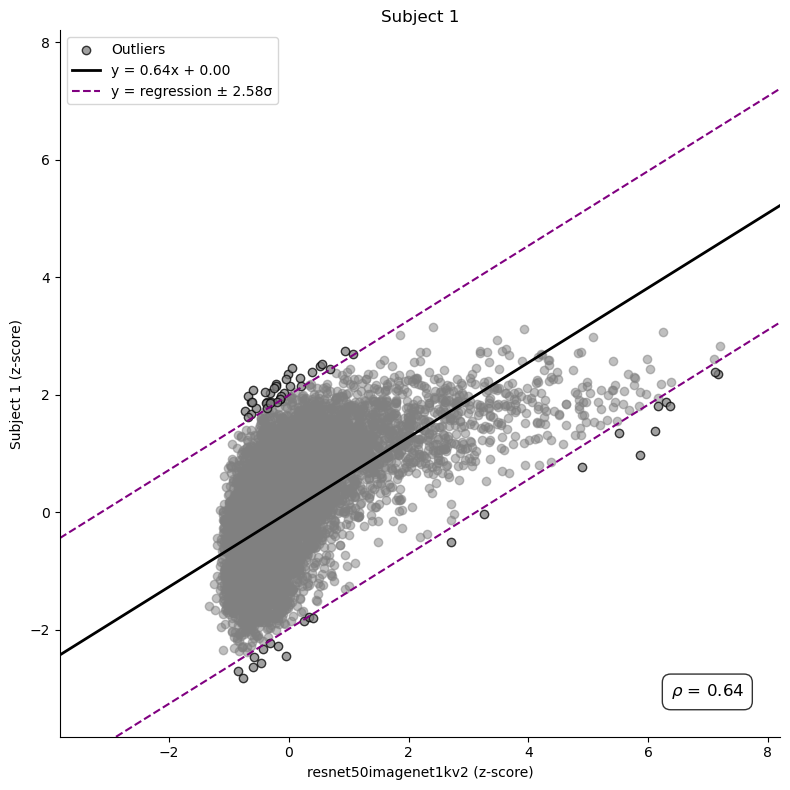

In [122]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))

# Fit the model using statsmodels (now with intercept)
X_with_intercept = sm.add_constant(X)
ols_model = sm.OLS(y, X_with_intercept).fit()
slope = ols_model.params[1].item()
intercept = ols_model.params[0].item()
print(ols_model.summary())

# Parameters
standardized_residual_threshold = 2.58
n = len(X)  # number of data points
k = 1   # number of predictors
# Degrees of freedom
df = n - k - 1
# Two-tailed p-value
p_value = 2 * (1 - stats.t.cdf(standardized_residual_threshold, df))
print(f"P-value: {p_value:.4f}")

# Standardized residuals
standardized_residuals = ols_model.get_influence().resid_studentized_internal
outliers = np.abs(standardized_residuals) > standardized_residual_threshold

# Regression line with intercept
regression_line = slope * X + intercept
pearson_rho = np.corrcoef(X, y)[0, 1]

# Calculate prediction bounds based on standardized residuals
residual_std = np.std(y - regression_line)
upper_bound = standardized_residual_threshold * residual_std
lower_bound = -standardized_residual_threshold * residual_std

subject_model_outliers = standardized_residuals > standardized_residual_threshold
model_subject_outliers = standardized_residuals < -standardized_residual_threshold
s1_outliers_dict[subject] = {
    'all_outliers': outliers,
    'subject>model': subject_model_outliers,
    'model>subject': model_subject_outliers,
    'subject_normed_responses': y,
    'model_normed_responses': X,
    'slope': slope,
    'intercept': intercept,
    'pearson_rho': pearson_rho,
    'nsdid_map': subject_stim_map
}

# Plot scatter points
ax.scatter(normalized_model_data[~outliers], normalized_subject_data[~outliers], alpha=0.5, color='gray')
ax.scatter(normalized_model_data[outliers], normalized_subject_data[outliers], alpha=0.75, color='gray', edgecolors='black', label='Outliers')

# Set equal axes limits
axis_min = min(normalized_model_data.min().item(), normalized_subject_data.min().item())
axis_max = max(normalized_model_data.max().item(), normalized_subject_data.max().item())
margin = 0.1 * (axis_max - axis_min)
ax.set_xlim(axis_min - margin, axis_max + margin)
ax.set_ylim(axis_min - margin, axis_max + margin)

# Get the actual axis limits for line plotting
x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()
x_vals = np.linspace(x_min, x_max, 100)

# Plot regression line with intercept
ax.plot(x_vals, slope * x_vals + intercept, color='k', linewidth=2, 
    label=f'y = {slope:.2f}x + {intercept:.2f}')

# Plot bounds based on standardized residual threshold
ax.plot(x_vals, slope * x_vals + intercept + upper_bound, color='purple', linestyle='--', 
        label=f"y = regression ± {standardized_residual_threshold:.2f}σ")
ax.plot(x_vals, slope * x_vals + intercept + lower_bound, color='purple', linestyle='--')

ax.set_title(f'Subject {subject}')
ax.set_xlabel(f'{test_model_name} (z-score)')
ax.set_ylabel(f'Subject {subject} (z-score)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend()

# Add Pearson correlation to bottom right corner
ax.text(0.95, 0.05, rf'$\rho$ = {pearson_rho:.2f}', 
    horizontalalignment='right', 
    verticalalignment='bottom', 
    transform=ax.transAxes, 
    fontsize=12, 
    bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

plt.tight_layout()
plt.show()

In [ ]:
subject_normed_responses = s1_outliers_dict[subject]['subject_normed_responses']
model_normed_responses = s1_outliers_dict[subject]['model_normed_responses']
subject_higherthan_model_outliers = s1_outliers_dict[subject]['subject>model']
model_higherthan_subject_outliers = s1_outliers_dict[subject]['model>subject']
# Get the indices of outliers where subject > model
outlier_indices = np.where(subject_higherthan_model_outliers)[0]

# If no outliers found, print a message
if len(outlier_indices) == 0:
    print("No outliers found where subject > model")
else:
    # Sort outliers by their standardized residuals (descending)
    sorted_outlier_indices = outlier_indices[np.argsort(-standardized_residuals[outlier_indices])]
    
    # Take top 25 outliers (or all if less than 25)
    top_25_indices = sorted_outlier_indices[:25]
    
    # Get nsdIds for these outliers
    top_25_nsdids = subject_stim_map['nsdId'].iloc[top_25_indices].values
    
    # Create a 5x5 grid to display images
    fig, axes = plt.subplots(5, 5, figsize=(15, 15))
    
    # Flatten the axes for easier iteration
    axes = axes.flatten()
    
    # Loop through the top 25 outliers and display images
    for i, nsdid in enumerate(top_25_nsdids):
        if i >= 25:  # Just to be safe
            break
            
        # Get the image from allstim
        img = allstim[nsdid]
        
        # Display the image
        axes[i].imshow(img)
        axes[i].set_title(f"NSD ID: {nsdid}", fontsize=10)
        axes[i].axis('off')
        
        # Get standardized residual value
        res_value = standardized_residuals[top_25_indices[i]]
        axes[i].set_xlabel(f"Res: {res_value:.2f}", fontsize=8)
    
    # Turn off any unused subplots
    for j in range(len(top_25_nsdids), 25):
        axes[j].axis('off')
    
    plt.tight_layout()
    plt.suptitle(f"Top 25 Images where Subject {subject} > Model Responses", y=1.02, fontsize=16)
    plt.show()

# Now do the same for images where model > subject (model_higherthan_subject_outliers)
# Get the indices of outliers where model > subject
model_higher_indices = np.where(model_higherthan_subject_outliers)[0]

if len(model_higher_indices) == 0:
    print("No outliers found where model > subject")
else:
    # Sort outliers by their standardized residuals (ascending, since these are negative residuals)
    sorted_model_higher_indices = model_higher_indices[np.argsort(standardized_residuals[model_higher_indices])]
    
    # Take top 25 outliers (or all if less than 25)
    top_25_model_indices = sorted_model_higher_indices[:25]
    
    # Get nsdIds for these outliers
    top_25_model_nsdids = subject_stim_map['nsdId'].iloc[top_25_model_indices].values
    
    # Create a 5x5 grid to display images
    fig, axes = plt.subplots(5, 5, figsize=(15, 15))
    
    # Flatten the axes for easier iteration
    axes = axes.flatten()
    
    # Loop through the top 25 outliers and display images
    for i, nsdid in enumerate(top_25_model_nsdids):
        if i >= 25:  # Just to be safe
            break
            
        # Get the image from allstim
        img = allstim[nsdid]
        
        # Display the image
        axes[i].imshow(img)
        axes[i].set_title(f"NSD ID: {nsdid}", fontsize=10)
        axes[i].axis('off')
        
        # Get standardized residual value
        res_value = standardized_residuals[top_25_model_indices[i]]
        axes[i].set_xlabel(f"Res: {res_value:.2f}", fontsize=8)
    
    # Turn off any unused subplots
    for j in range(len(top_25_model_nsdids), 25):
        axes[j].axis('off')
    
    plt.tight_layout()
    plt.suptitle(f"Top 25 Images where Model > Subject {subject} Responses", y=1.02, fontsize=16)
    plt.show()

# Finally, get the "least extreme" outliers (closest to the regression line but still outside bounds)
# For model > subject outliers, we take the ones closest to zero (least negative)
if len(model_higher_indices) > 25:
    least_extreme_indices = sorted_model_higher_indices[-25:]  # Last 25 are closest to zero
    
    # Get nsdIds for these least extreme outliers
    least_extreme_nsdids = subject_stim_map['nsdId'].iloc[least_extreme_indices].values
    
    # Create a 5x5 grid to display images
    fig, axes = plt.subplots(5, 5, figsize=(15, 15))
    
    # Flatten the axes for easier iteration
    axes = axes.flatten()
    
    # Loop through the least extreme outliers and display images
    for i, nsdid in enumerate(least_extreme_nsdids):
        if i >= 25:  # Just to be safe
            break
            
        # Get the image from allstim
        img = allstim[nsdid]
        
        # Display the image
        axes[i].imshow(img)
        axes[i].set_title(f"NSD ID: {nsdid}", fontsize=10)
        axes[i].axis('off')
        
        # Get standardized residual value
        res_value = standardized_residuals[least_extreme_indices[i]]
        axes[i].set_xlabel(f"Res: {res_value:.2f}", fontsize=8)
    
    # Turn off any unused subplots
    for j in range(len(least_extreme_nsdids), 25):
        axes[j].axis('off')
    
    plt.tight_layout()
    plt.suptitle(f"25 Least Extreme Outliers where Model > Subject {subject}", y=1.02, fontsize=16)
    plt.show()

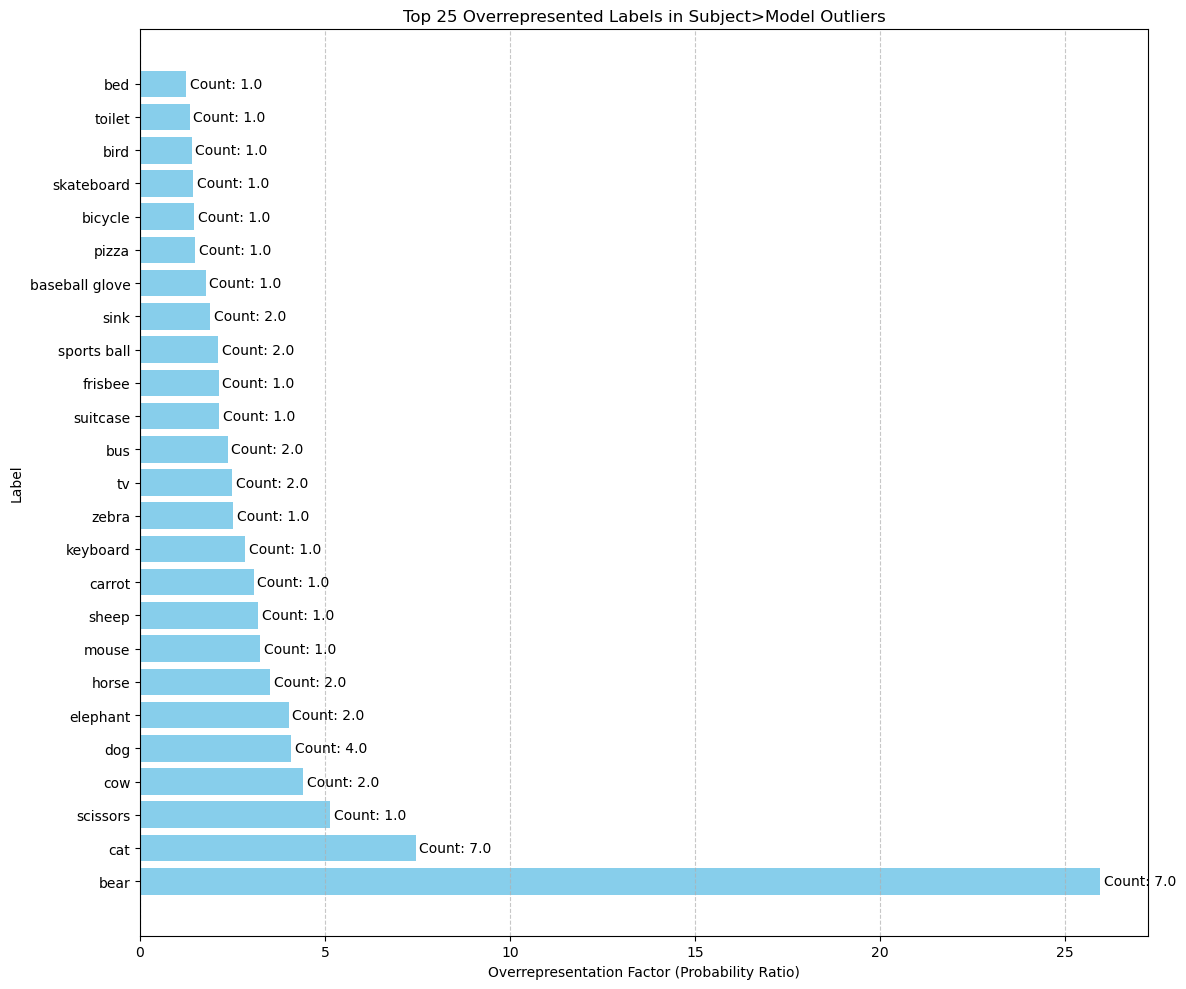

Total number of outliers where subject > model: 35
Total number of labels in outliers: 70
Average labels per outlier image: 2.00


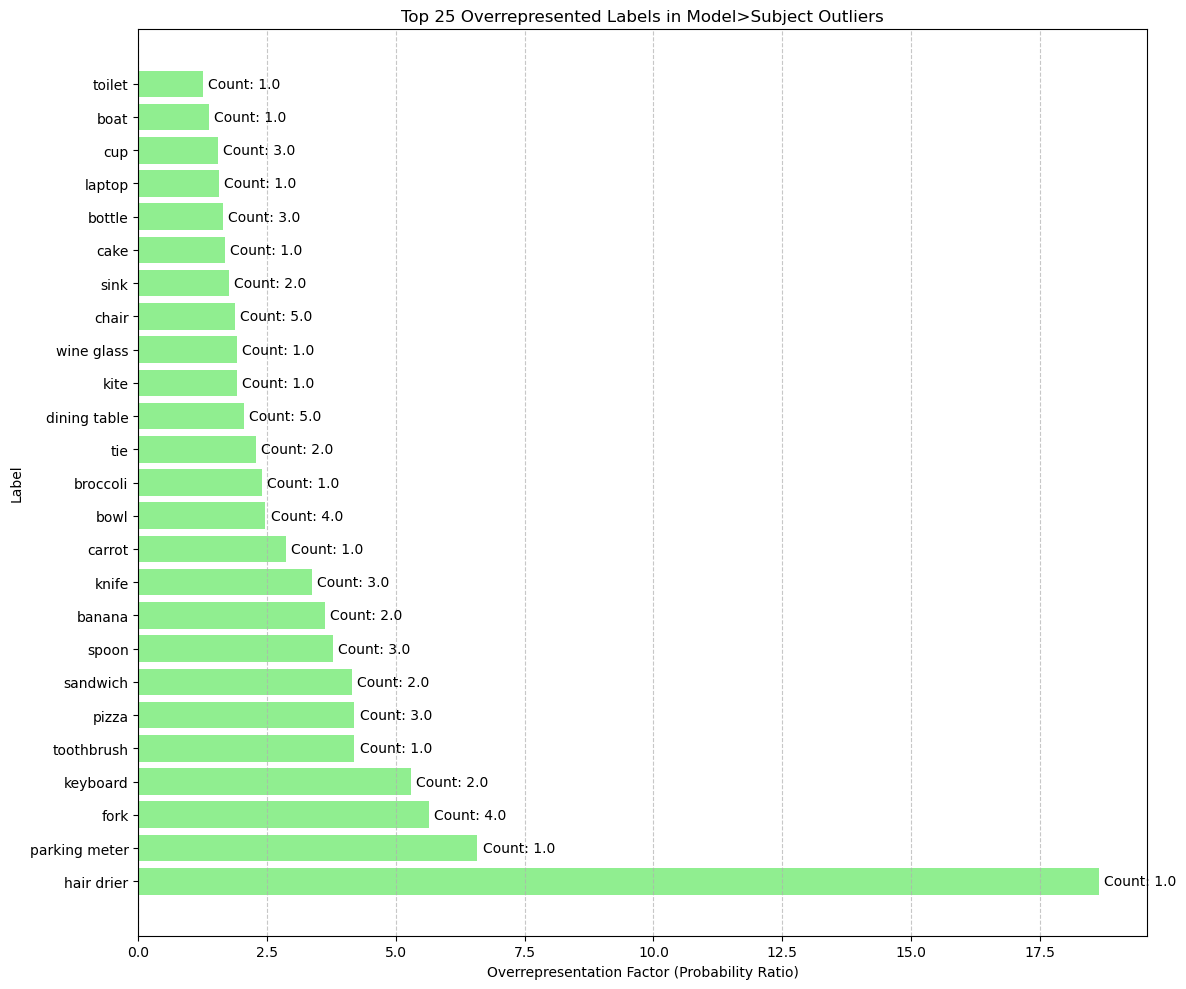

Total number of outliers where model > subject: 23
Total number of labels in these outliers: 75
Average labels per outlier image: 3.26


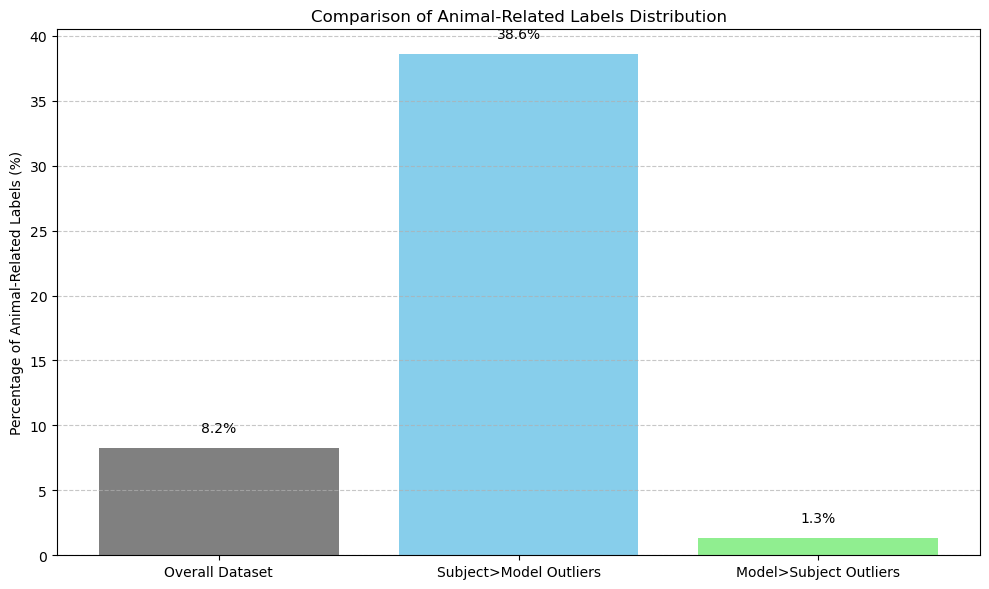

Animal-related categories: bird, cat, dog, horse, sheep, cow, elephant, bear, zebra, giraffe
Percentage of animal labels in overall dataset: 8.23%
Percentage of animal labels in subject>model outliers: 38.57%
Percentage of animal labels in model>subject outliers: 1.33%


In [ ]:
# Get all labels across the 9000 stimuli dataset
all_labels = []
for labels_list in subject_stim_map_9000_labels['labels']:
    all_labels.extend(labels_list)

# Count frequency of each label in the full dataset
all_labels_counter = Counter(all_labels)
total_labels = len(all_labels)

# Get indices where subject response is higher than model
outlier_indices = np.where(subject_higherthan_model_outliers)[0]

# Extract labels from outliers
outlier_labels = []
for idx in outlier_indices:
    outlier_labels.extend(subject_stim_map_9000_labels['labels'].iloc[idx])

# Count frequency of each label in outliers
outlier_labels_counter = Counter(outlier_labels)
total_outlier_labels = len(outlier_labels)

# Calculate the normalized probability ratio
# (probability of label in outliers / probability of label in overall dataset)
label_ratios = {}
for label, count in outlier_labels_counter.items():
    # Calculate probabilities
    prob_in_outliers = count / total_outlier_labels
    prob_in_dataset = all_labels_counter.get(label, 0) / total_labels
    
    # Calculate ratio (overrepresentation factor)
    if prob_in_dataset > 0:
        ratio = prob_in_outliers / prob_in_dataset
    else:
        ratio = float('inf')  # Avoid division by zero
    
    # Store label, count in outliers, and ratio
    label_ratios[label] = {
        'count': count,
        'ratio': ratio,
        'prob_in_outliers': prob_in_outliers,
        'prob_in_dataset': prob_in_dataset
    }

# Convert to DataFrame for easier manipulation
df_ratios = pd.DataFrame.from_dict(label_ratios, orient='index')

# Get top 25 overrepresented labels (by ratio)
top_25_overrepresented = df_ratios.sort_values('ratio', ascending=False).head(25)

# Create a horizontal bar chart
plt.figure(figsize=(12, 10))
plt.barh(top_25_overrepresented.index, top_25_overrepresented['ratio'], color='skyblue')
plt.xlabel('Overrepresentation Factor (Probability Ratio)')
plt.ylabel('Label')
plt.title('Top 25 Overrepresented Labels in Subject>Model Outliers')
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Add count annotations
for i, (label, row) in enumerate(top_25_overrepresented.iterrows()):
    plt.text(row['ratio'] + 0.1, i, f"Count: {row['count']}", va='center')

plt.tight_layout()
plt.show()

# Print summary statistics
print(f"Total number of outliers where subject > model: {len(outlier_indices)}")
print(f"Total number of labels in outliers: {total_outlier_labels}")
print(f"Average labels per outlier image: {total_outlier_labels / max(1, len(outlier_indices)):.2f}")

# Now do the same for model > subject outliers
model_outlier_indices = np.where(model_higherthan_subject_outliers)[0]
model_outlier_labels = []
for idx in model_outlier_indices:
    model_outlier_labels.extend(subject_stim_map_9000_labels['labels'].iloc[idx])

model_outlier_labels_counter = Counter(model_outlier_labels)
total_model_outlier_labels = len(model_outlier_labels)

# Calculate ratios for model > subject
model_label_ratios = {}
for label, count in model_outlier_labels_counter.items():
    prob_in_outliers = count / total_model_outlier_labels
    prob_in_dataset = all_labels_counter.get(label, 0) / total_labels
    
    if prob_in_dataset > 0:
        ratio = prob_in_outliers / prob_in_dataset
    else:
        ratio = float('inf')
    
    model_label_ratios[label] = {
        'count': count,
        'ratio': ratio,
        'prob_in_outliers': prob_in_outliers,
        'prob_in_dataset': prob_in_dataset
    }

df_model_ratios = pd.DataFrame.from_dict(model_label_ratios, orient='index')
top_25_model_overrepresented = df_model_ratios.sort_values('ratio', ascending=False).head(25)

# Create a horizontal bar chart for model > subject
plt.figure(figsize=(12, 10))
plt.barh(top_25_model_overrepresented.index, top_25_model_overrepresented['ratio'], color='lightgreen')
plt.xlabel('Overrepresentation Factor (Probability Ratio)')
plt.ylabel('Label')
plt.title('Top 25 Overrepresented Labels in Model>Subject Outliers')
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Add count annotations
for i, (label, row) in enumerate(top_25_model_overrepresented.iterrows()):
    plt.text(row['ratio'] + 0.1, i, f"Count: {row['count']}", va='center')

plt.tight_layout()
plt.show()

print(f"Total number of outliers where model > subject: {len(model_outlier_indices)}")
print(f"Total number of labels in these outliers: {total_model_outlier_labels}")
print(f"Average labels per outlier image: {total_model_outlier_labels / max(1, len(model_outlier_indices)):.2f}")

# Compare animal-related vs non-animal categories
animal_categories = coco_animal_labels
animal_categories_set = set(animal_categories)

# Count animal labels in overall dataset
animal_labels_count = sum(1 for label in all_labels if label in animal_categories_set)
animal_labels_percentage = animal_labels_count / total_labels * 100

# Count animal labels in subject > model outliers
animal_outlier_count = sum(1 for label in outlier_labels if label in animal_categories_set)
animal_outlier_percentage = animal_outlier_count / total_outlier_labels * 100

# Count animal labels in model > subject outliers
animal_model_outlier_count = sum(1 for label in model_outlier_labels if label in animal_categories_set)
animal_model_outlier_percentage = animal_model_outlier_count / total_model_outlier_labels * 100

# Plot comparison
categories = ['Overall Dataset', 'Subject>Model Outliers', 'Model>Subject Outliers']
animal_percentages = [animal_labels_percentage, animal_outlier_percentage, animal_model_outlier_percentage]

plt.figure(figsize=(10, 6))
bars = plt.bar(categories, animal_percentages, color=['gray', 'skyblue', 'lightgreen'])
plt.ylabel('Percentage of Animal-Related Labels (%)')
plt.title('Comparison of Animal-Related Labels Distribution')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add percentage annotations
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 1,
             f'{height:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

print(f"Animal-related categories: {', '.join(animal_categories)}")
print(f"Percentage of animal labels in overall dataset: {animal_labels_percentage:.2f}%")
print(f"Percentage of animal labels in subject>model outliers: {animal_outlier_percentage:.2f}%")
print(f"Percentage of animal labels in model>subject outliers: {animal_model_outlier_percentage:.2f}%")

## Final

In [ ]:
stim1000_nsdids = nsd_ds_utils.get_subset_nsdids(paths.NSD_DIR, 1000)
sbj_outliers_dict = {}

for subject in train_subjects:
    # Get subject data
    subject_data, subject_stim_map = nsd.get_betas(
        paths.NSD_DIR, subject, froi=froi, tthreshold=tthreshold, voxels=False, repetition_mean=True
    )
    # Filter out nsdIds that are in stim1000_nsdids
    subject_stim_map_9000 = subject_stim_map[~subject_stim_map['nsdId'].isin(stim1000_nsdids)]
    subject_data_9000 = subject_data[~subject_stim_map['nsdId'].isin(stim1000_nsdids)]
    # Add labels
    subject_stim_map_9000_labels = add_image_labels_to_df(subject_stim_map_9000)

    # Get model data
    model_subject_data_9000 = model_allnsdstim_activations.mean(axis=-1)[list(subject_stim_map_9000['nsdId'])]

    # Normalize the data
    normalized_model_data = z_score_normalize(model_subject_data_9000)
    normalized_subject_data = z_score_normalize(subject_data_9000)
    X = normalized_model_data.numpy()
    y = normalized_subject_data.numpy()

    fig, ax = plt.subplots(1, 1, figsize=(8, 8))

    # Fit the model using statsmodels (now with intercept)
    X_with_intercept = sm.add_constant(X)
    ols_model = sm.OLS(y, X_with_intercept).fit()
    slope = ols_model.params[1].item()
    intercept = ols_model.params[0].item()
    print(ols_model.summary())

    # Parameters
    standardized_residual_threshold = 2.58
    n = len(X)  # number of data points
    k = 1   # number of predictors
    # Degrees of freedom
    df = n - k - 1
    # Two-tailed p-value
    p_value = 2 * (1 - stats.t.cdf(standardized_residual_threshold, df))
    print(f"P-value: {p_value:.4f}")

    # Standardized residuals
    standardized_residuals = ols_model.get_influence().resid_studentized_internal
    outliers = np.abs(standardized_residuals) > standardized_residual_threshold

    # Regression line with intercept
    regression_line = slope * X + intercept
    pearson_rho = np.corrcoef(X, y)[0, 1]

    # Calculate prediction bounds based on standardized residuals
    residual_std = np.std(y - regression_line)
    upper_bound = standardized_residual_threshold * residual_std
    lower_bound = -standardized_residual_threshold * residual_std

    subject_model_outliers = standardized_residuals > standardized_residual_threshold
    model_subject_outliers = standardized_residuals < -standardized_residual_threshold
    sbj_outliers_dict[subject] = {
        'all_outliers': outliers,
        'subject>model': subject_model_outliers,
        'model>subject': model_subject_outliers,
        'subject_normed_responses': y,
        'model_normed_responses': X,
        'slope': slope,
        'intercept': intercept,
        'pearson_rho': pearson_rho,
        'nsdid_map': subject_stim_map
    }

    # Plot scatter points
    ax.scatter(normalized_model_data[~outliers], normalized_subject_data[~outliers], alpha=0.5, color='gray')
    ax.scatter(normalized_model_data[outliers], normalized_subject_data[outliers], alpha=0.75, color='gray', edgecolors='black', label='Outliers')

    # Set equal axes limits
    axis_min = min(normalized_model_data.min().item(), normalized_subject_data.min().item())
    axis_max = max(normalized_model_data.max().item(), normalized_subject_data.max().item())
    margin = 0.1 * (axis_max - axis_min)
    ax.set_xlim(axis_min - margin, axis_max + margin)
    ax.set_ylim(axis_min - margin, axis_max + margin)

    # Get the actual axis limits for line plotting
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    x_vals = np.linspace(x_min, x_max, 100)

    # Plot regression line with intercept
    ax.plot(x_vals, slope * x_vals + intercept, color='k', linewidth=2, 
        label=f'y = {slope:.2f}x + {intercept:.2f}')

    # Plot bounds based on standardized residual threshold
    ax.plot(x_vals, slope * x_vals + intercept + upper_bound, color='purple', linestyle='--', 
            label=f"y = regression ± {standardized_residual_threshold:.2f}σ")
    ax.plot(x_vals, slope * x_vals + intercept + lower_bound, color='purple', linestyle='--')

    ax.set_title(f'Subject {subject}')
    ax.set_xlabel(f'{test_model_name} (z-score)')
    ax.set_ylabel(f'Subject {subject} (z-score)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend()

    # Add Pearson correlation to bottom right corner
    ax.text(0.95, 0.05, rf'$\rho$ = {pearson_rho:.2f}', 
        horizontalalignment='right', 
        verticalalignment='bottom', 
        transform=ax.transAxes, 
        fontsize=12, 
        bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

    plt.tight_layout()
    plt.show()

    subject_normed_responses = sbj_outliers_dict[subject]['subject_normed_responses']
    model_normed_responses = sbj_outliers_dict[subject]['model_normed_responses']
    subject_higherthan_model_outliers = sbj_outliers_dict[subject]['subject>model']
    model_higherthan_subject_outliers = sbj_outliers_dict[subject]['model>subject']
    # Get the indices of outliers where subject > model
    outlier_indices = np.where(subject_higherthan_model_outliers)[0]

    # If no outliers found, print a message
    if len(outlier_indices) == 0:
        print("No outliers found where subject > model")
    else:
        # Sort outliers by their standardized residuals (descending)
        sorted_outlier_indices = outlier_indices[np.argsort(-standardized_residuals[outlier_indices])]
        
        # Take top 25 outliers (or all if less than 25)
        top_25_indices = sorted_outlier_indices[:25]
        
        # Get nsdIds for these outliers
        top_25_nsdids = subject_stim_map['nsdId'].iloc[top_25_indices].values
        
        # Create a 5x5 grid to display images
        fig, axes = plt.subplots(5, 5, figsize=(15, 15))
        
        # Flatten the axes for easier iteration
        axes = axes.flatten()
        
        # Loop through the top 25 outliers and display images
        for i, nsdid in enumerate(top_25_nsdids):
            if i >= 25:  # Just to be safe
                break
                
            # Get the image from allstim
            img = allstim[nsdid]
            
            # Display the image
            axes[i].imshow(img)
            axes[i].set_title(f"NSD ID: {nsdid}", fontsize=10)
            axes[i].axis('off')
            
            # Get standardized residual value
            res_value = standardized_residuals[top_25_indices[i]]
            axes[i].set_xlabel(f"Res: {res_value:.2f}", fontsize=8)
        
        # Turn off any unused subplots
        for j in range(len(top_25_nsdids), 25):
            axes[j].axis('off')
        
        plt.tight_layout()
        plt.suptitle(f"Top 25 Images where Subject {subject} > Model Responses", y=1.02, fontsize=16)
        plt.show()

    # Now do the same for images where model > subject (model_higherthan_subject_outliers)
    # Get the indices of outliers where model > subject
    model_higher_indices = np.where(model_higherthan_subject_outliers)[0]

    if len(model_higher_indices) == 0:
        print("No outliers found where model > subject")
    else:
        # Sort outliers by their standardized residuals (ascending, since these are negative residuals)
        sorted_model_higher_indices = model_higher_indices[np.argsort(standardized_residuals[model_higher_indices])]
        
        # Take top 25 outliers (or all if less than 25)
        top_25_model_indices = sorted_model_higher_indices[:25]
        
        # Get nsdIds for these outliers
        top_25_model_nsdids = subject_stim_map['nsdId'].iloc[top_25_model_indices].values
        
        # Create a 5x5 grid to display images
        fig, axes = plt.subplots(5, 5, figsize=(15, 15))
        
        # Flatten the axes for easier iteration
        axes = axes.flatten()
        
        # Loop through the top 25 outliers and display images
        for i, nsdid in enumerate(top_25_model_nsdids):
            if i >= 25:  # Just to be safe
                break
                
            # Get the image from allstim
            img = allstim[nsdid]
            
            # Display the image
            axes[i].imshow(img)
            axes[i].set_title(f"NSD ID: {nsdid}", fontsize=10)
            axes[i].axis('off')
            
            # Get standardized residual value
            res_value = standardized_residuals[top_25_model_indices[i]]
            axes[i].set_xlabel(f"Res: {res_value:.2f}", fontsize=8)
        
        # Turn off any unused subplots
        for j in range(len(top_25_model_nsdids), 25):
            axes[j].axis('off')
        
        plt.tight_layout()
        plt.suptitle(f"Top 25 Images where Model > Subject {subject} Responses", y=1.02, fontsize=16)
        plt.show()

    # Finally, get the "least extreme" outliers (closest to the regression line but still outside bounds)
    # For model > subject outliers, we take the ones closest to zero (least negative)
    if len(model_higher_indices) > 25:
        least_extreme_indices = sorted_model_higher_indices[-25:]  # Last 25 are closest to zero
        
        # Get nsdIds for these least extreme outliers
        least_extreme_nsdids = subject_stim_map['nsdId'].iloc[least_extreme_indices].values
        
        # Create a 5x5 grid to display images
        fig, axes = plt.subplots(5, 5, figsize=(15, 15))
        
        # Flatten the axes for easier iteration
        axes = axes.flatten()
        
        # Loop through the least extreme outliers and display images
        for i, nsdid in enumerate(least_extreme_nsdids):
            if i >= 25:  # Just to be safe
                break
                
            # Get the image from allstim
            img = allstim[nsdid]
            
            # Display the image
            axes[i].imshow(img)
            axes[i].set_title(f"NSD ID: {nsdid}", fontsize=10)
            axes[i].axis('off')
            
            # Get standardized residual value
            res_value = standardized_residuals[least_extreme_indices[i]]
            axes[i].set_xlabel(f"Res: {res_value:.2f}", fontsize=8)
        
        # Turn off any unused subplots
        for j in range(len(least_extreme_nsdids), 25):
            axes[j].axis('off')
        
        plt.tight_layout()
        plt.suptitle(f"25 Least Extreme Outliers where Model > Subject {subject}", y=1.02, fontsize=16)
        plt.show()

    # Get all labels across the 9000 stimuli dataset
    all_labels = []
    for labels_list in subject_stim_map_9000_labels['labels']:
        all_labels.extend(labels_list)

    # Count frequency of each label in the full dataset
    all_labels_counter = Counter(all_labels)
    total_labels = len(all_labels)

    # Get indices where subject response is higher than model
    outlier_indices = np.where(subject_higherthan_model_outliers)[0]

    # Extract labels from outliers
    outlier_labels = []
    for idx in outlier_indices:
        outlier_labels.extend(subject_stim_map_9000_labels['labels'].iloc[idx])

    # Count frequency of each label in outliers
    outlier_labels_counter = Counter(outlier_labels)
    total_outlier_labels = len(outlier_labels)

    # Calculate the normalized probability ratio
    # (probability of label in outliers / probability of label in overall dataset)
    label_ratios = {}
    for label, count in outlier_labels_counter.items():
        # Calculate probabilities
        prob_in_outliers = count / total_outlier_labels
        prob_in_dataset = all_labels_counter.get(label, 0) / total_labels
        
        # Calculate ratio (overrepresentation factor)
        if prob_in_dataset > 0:
            ratio = prob_in_outliers / prob_in_dataset
        else:
            ratio = float('inf')  # Avoid division by zero
        
        # Store label, count in outliers, and ratio
        label_ratios[label] = {
            'count': count,
            'ratio': ratio,
            'prob_in_outliers': prob_in_outliers,
            'prob_in_dataset': prob_in_dataset
        }

    # Convert to DataFrame for easier manipulation
    df_ratios = pd.DataFrame.from_dict(label_ratios, orient='index')

    # Get top 25 overrepresented labels (by ratio)
    top_25_overrepresented = df_ratios.sort_values('ratio', ascending=False).head(25)

    # Create a horizontal bar chart
    plt.figure(figsize=(12, 10))
    plt.barh(top_25_overrepresented.index, top_25_overrepresented['ratio'], color='skyblue')
    plt.xlabel('Overrepresentation Factor (Probability Ratio)')
    plt.ylabel('Label')
    plt.title('Top 25 Overrepresented Labels in Subject>Model Outliers')
    plt.grid(axis='x', linestyle='--', alpha=0.7)

    # Add count annotations
    for i, (label, row) in enumerate(top_25_overrepresented.iterrows()):
        plt.text(row['ratio'] + 0.1, i, f"Count: {row['count']}", va='center')

    plt.tight_layout()
    plt.show()

    # Print summary statistics
    print(f"Total number of outliers where subject > model: {len(outlier_indices)}")
    print(f"Total number of labels in outliers: {total_outlier_labels}")
    print(f"Average labels per outlier image: {total_outlier_labels / max(1, len(outlier_indices)):.2f}")

    # Now do the same for model > subject outliers
    model_outlier_indices = np.where(model_higherthan_subject_outliers)[0]
    model_outlier_labels = []
    for idx in model_outlier_indices:
        model_outlier_labels.extend(subject_stim_map_9000_labels['labels'].iloc[idx])

    model_outlier_labels_counter = Counter(model_outlier_labels)
    total_model_outlier_labels = len(model_outlier_labels)

    # Calculate ratios for model > subject
    model_label_ratios = {}
    for label, count in model_outlier_labels_counter.items():
        prob_in_outliers = count / total_model_outlier_labels
        prob_in_dataset = all_labels_counter.get(label, 0) / total_labels
        
        if prob_in_dataset > 0:
            ratio = prob_in_outliers / prob_in_dataset
        else:
            ratio = float('inf')
        
        model_label_ratios[label] = {
            'count': count,
            'ratio': ratio,
            'prob_in_outliers': prob_in_outliers,
            'prob_in_dataset': prob_in_dataset
        }

    df_model_ratios = pd.DataFrame.from_dict(model_label_ratios, orient='index')
    top_25_model_overrepresented = df_model_ratios.sort_values('ratio', ascending=False).head(25)

    # Create a horizontal bar chart for model > subject
    plt.figure(figsize=(12, 10))
    plt.barh(top_25_model_overrepresented.index, top_25_model_overrepresented['ratio'], color='lightgreen')
    plt.xlabel('Overrepresentation Factor (Probability Ratio)')
    plt.ylabel('Label')
    plt.title('Top 25 Overrepresented Labels in Model>Subject Outliers')
    plt.grid(axis='x', linestyle='--', alpha=0.7)

    # Add count annotations
    for i, (label, row) in enumerate(top_25_model_overrepresented.iterrows()):
        plt.text(row['ratio'] + 0.1, i, f"Count: {row['count']}", va='center')

    plt.tight_layout()
    plt.show()

    print(f"Total number of outliers where model > subject: {len(model_outlier_indices)}")
    print(f"Total number of labels in these outliers: {total_model_outlier_labels}")
    print(f"Average labels per outlier image: {total_model_outlier_labels / max(1, len(model_outlier_indices)):.2f}")

    # Compare animal-related vs non-animal categories
    animal_categories = coco_animal_labels
    animal_categories_set = set(animal_categories)

    # Count animal labels in overall dataset
    animal_labels_count = sum(1 for label in all_labels if label in animal_categories_set)
    animal_labels_percentage = animal_labels_count / total_labels * 100

    # Count animal labels in subject > model outliers
    animal_outlier_count = sum(1 for label in outlier_labels if label in animal_categories_set)
    animal_outlier_percentage = animal_outlier_count / total_outlier_labels * 100

    # Count animal labels in model > subject outliers
    animal_model_outlier_count = sum(1 for label in model_outlier_labels if label in animal_categories_set)
    animal_model_outlier_percentage = animal_model_outlier_count / total_model_outlier_labels * 100

    # Plot comparison
    categories = ['Overall Dataset', 'Subject>Model Outliers', 'Model>Subject Outliers']
    animal_percentages = [animal_labels_percentage, animal_outlier_percentage, animal_model_outlier_percentage]

    plt.figure(figsize=(10, 6))
    bars = plt.bar(categories, animal_percentages, color=['gray', 'skyblue', 'lightgreen'])
    plt.ylabel('Percentage of Animal-Related Labels (%)')
    plt.title('Comparison of Animal-Related Labels Distribution')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    # Add percentage annotations
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + 1,
                f'{height:.1f}%', ha='center', va='bottom')

    plt.tight_layout()
    plt.show()

    print(f"Animal-related categories: {', '.join(animal_categories)}")
    print(f"Percentage of animal labels in overall dataset: {animal_labels_percentage:.2f}%")
    print(f"Percentage of animal labels in subject>model outliers: {animal_outlier_percentage:.2f}%")
    print(f"Percentage of animal labels in model>subject outliers: {animal_model_outlier_percentage:.2f}%")

In [ ]:
stim1000_nsdids = nsd_ds_utils.get_subset_nsdids(paths.NSD_DIR, 1000)
sbj_outliers_dict = {}

fig, axes = plt.subplots(1, 4, figsize=(32, 8))
axes = axes.flatten()

# Combined counters for all subjects
all_combined_labels = []
subject_higher_combined_labels = []
model_higher_combined_labels = []

for i, subject in enumerate(train_subjects):
    # Get subject data
    subject_data, subject_stim_map = nsd.get_betas(
        paths.NSD_DIR, subject, froi=froi, tthreshold=tthreshold, voxels=False, repetition_mean=True
    )
    # Filter out nsdIds that are in stim1000_nsdids
    subject_stim_map_9000 = subject_stim_map[~subject_stim_map['nsdId'].isin(stim1000_nsdids)]
    subject_data_9000 = subject_data[~subject_stim_map['nsdId'].isin(stim1000_nsdids)]
    # Add labels
    subject_stim_map_9000_labels = add_image_labels_to_df(subject_stim_map_9000)

    # Get model data
    model_subject_data_9000 = model_allnsdstim_activations.mean(axis=-1)[list(subject_stim_map_9000['nsdId'])]

    # Normalize the data
    normalized_model_data = z_score_normalize(model_subject_data_9000)
    normalized_subject_data = z_score_normalize(subject_data_9000)
    X = normalized_model_data.numpy()
    y = normalized_subject_data.numpy()

    # Fit the model using statsmodels (now with intercept)
    X_with_intercept = sm.add_constant(X)
    ols_model = sm.OLS(y, X_with_intercept).fit()
    slope = ols_model.params[1].item()
    intercept = ols_model.params[0].item()

    # Parameters
    standardized_residual_threshold = 2.58
    n = len(X)  # number of data points
    k = 1   # number of predictors
    # Degrees of freedom
    df = n - k - 1
    
    # Standardized residuals
    standardized_residuals = ols_model.get_influence().resid_studentized_internal
    outliers = np.abs(standardized_residuals) > standardized_residual_threshold

    # Regression line with intercept
    regression_line = slope * X + intercept
    pearson_rho = np.corrcoef(X, y)[0, 1]

    # Calculate prediction bounds based on standardized residuals
    residual_std = np.std(y - regression_line)
    upper_bound = standardized_residual_threshold * residual_std
    lower_bound = -standardized_residual_threshold * residual_std

    subject_model_outliers = standardized_residuals > standardized_residual_threshold
    model_subject_outliers = standardized_residuals < -standardized_residual_threshold
    sbj_outliers_dict[subject] = {
        'all_outliers': outliers,
        'subject>model': subject_model_outliers,
        'model>subject': model_subject_outliers,
        'subject_normed_responses': y,
        'model_normed_responses': X,
        'slope': slope,
        'intercept': intercept,
        'pearson_rho': pearson_rho,
        'nsdid_map': subject_stim_map
    }

    # Plot scatter points in the corresponding subplot
    ax = axes[i]
    ax.scatter(normalized_model_data[~outliers], normalized_subject_data[~outliers], alpha=0.5, color='gray')
    ax.scatter(normalized_model_data[outliers], normalized_subject_data[outliers], alpha=0.75, color='gray', edgecolors='black', label='Outliers')

    # Set equal axes limits
    axis_min = min(normalized_model_data.min().item(), normalized_subject_data.min().item())
    axis_max = max(normalized_model_data.max().item(), normalized_subject_data.max().item())
    margin = 0.1 * (axis_max - axis_min)
    ax.set_xlim(axis_min - margin, axis_max + margin)
    ax.set_ylim(axis_min - margin, axis_max + margin)

    # Get the actual axis limits for line plotting
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    x_vals = np.linspace(x_min, x_max, 100)

    # Plot regression line with intercept
    ax.plot(x_vals, slope * x_vals + intercept, color='k', linewidth=2, 
        label=f'y = {slope:.2f}x + {intercept:.2f}')

    # Plot bounds based on standardized residual threshold
    ax.plot(x_vals, slope * x_vals + intercept + upper_bound, color='purple', linestyle='--', 
            label=f"y = regression ± {standardized_residual_threshold:.2f}σ")
    ax.plot(x_vals, slope * x_vals + intercept + lower_bound, color='purple', linestyle='--')

    ax.set_title(f'Subject {subject}')
    ax.set_xlabel(f'{test_model_name} (z-score)')
    ax.set_ylabel(f'Subject {subject} (z-score)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend()

    # Add Pearson correlation to bottom right corner
    ax.text(0.95, 0.05, rf'$\rho$ = {pearson_rho:.2f}', 
        horizontalalignment='right', 
        verticalalignment='bottom', 
        transform=ax.transAxes, 
        fontsize=12, 
        bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

    # Get all labels across the 9000 stimuli dataset for this subject
    all_labels = []
    for labels_list in subject_stim_map_9000_labels['labels']:
        all_labels.extend(labels_list)
    
    # Add to combined labels
    all_combined_labels.extend(all_labels)
    
    # Get indices where subject response is higher than model
    subject_higher_indices = np.where(subject_model_outliers)[0]
    
    # Extract labels from subject>model outliers
    subject_higher_labels = []
    for idx in subject_higher_indices:
        subject_higher_labels.extend(subject_stim_map_9000_labels['labels'].iloc[idx])
    
    # Add to combined labels
    subject_higher_combined_labels.extend(subject_higher_labels)
    
    # Get indices where model response is higher than subject
    model_higher_indices = np.where(model_subject_outliers)[0]
    
    # Extract labels from model>subject outliers
    model_higher_labels = []
    for idx in model_higher_indices:
        model_higher_labels.extend(subject_stim_map_9000_labels['labels'].iloc[idx])
    
    # Add to combined labels
    model_higher_combined_labels.extend(model_higher_labels)

plt.tight_layout()
plt.suptitle(f'Model-Subject Correlations for {test_model_name}', y=1.02, fontsize=16)
plt.show()

# Now analyze the combined label distributions
# Count frequency of each label in the full dataset
all_labels_counter = Counter(all_combined_labels)
total_labels = len(all_combined_labels)

# Count frequency of each label in subject>model outliers
subject_higher_counter = Counter(subject_higher_combined_labels)
total_subject_higher_labels = len(subject_higher_combined_labels)

# Count frequency of each label in model>subject outliers
model_higher_counter = Counter(model_higher_combined_labels)
total_model_higher_labels = len(model_higher_combined_labels)

# Calculate the normalized probability ratio for subject>model
subject_label_ratios = {}
for label, count in subject_higher_counter.items():
    prob_in_outliers = count / total_subject_higher_labels
    prob_in_dataset = all_labels_counter.get(label, 0) / total_labels
    
    if prob_in_dataset > 0:
        ratio = prob_in_outliers / prob_in_dataset
    else:
        ratio = float('inf')
    
    subject_label_ratios[label] = {
        'count': count,
        'ratio': ratio,
        'prob_in_outliers': prob_in_outliers,
        'prob_in_dataset': prob_in_dataset
    }

# Calculate the normalized probability ratio for model>subject
model_label_ratios = {}
for label, count in model_higher_counter.items():
    prob_in_outliers = count / total_model_higher_labels
    prob_in_dataset = all_labels_counter.get(label, 0) / total_labels
    
    if prob_in_dataset > 0:
        ratio = prob_in_outliers / prob_in_dataset
    else:
        ratio = float('inf')
    
    model_label_ratios[label] = {
        'count': count,
        'ratio': ratio,
        'prob_in_outliers': prob_in_outliers,
        'prob_in_dataset': prob_in_dataset
    }

# Convert to DataFrames
df_subject_ratios = pd.DataFrame.from_dict(subject_label_ratios, orient='index')
df_model_ratios = pd.DataFrame.from_dict(model_label_ratios, orient='index')

# Get top 25 overrepresented labels for both categories
top_25_subject = df_subject_ratios.sort_values('ratio', ascending=False).head(25)
top_25_model = df_model_ratios.sort_values('ratio', ascending=False).head(25)

# Create a figure with two subplots for the bar charts
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

# Plot Subject>Model overrepresented labels
ax1.barh(top_25_subject.index, top_25_subject['ratio'], color='skyblue')
ax1.set_xlabel('Overrepresentation Factor (Probability Ratio)')
ax1.set_ylabel('Label')
ax1.set_title('Top 25 Overrepresented Labels in Subject>Model Outliers')
ax1.grid(axis='x', linestyle='--', alpha=0.7)

# Add count annotations
for i, (label, row) in enumerate(top_25_subject.iterrows()):
    ax1.text(row['ratio'] + 0.1, i, f"Count: {row['count']}", va='center')

# Plot Model>Subject overrepresented labels
ax2.barh(top_25_model.index, top_25_model['ratio'], color='lightgreen')
ax2.set_xlabel('Overrepresentation Factor (Probability Ratio)')
ax2.set_ylabel('Label')
ax2.set_title('Top 25 Overrepresented Labels in Model>Subject Outliers')
ax2.grid(axis='x', linestyle='--', alpha=0.7)

# Add count annotations
for i, (label, row) in enumerate(top_25_model.iterrows()):
    ax2.text(row['ratio'] + 0.1, i, f"Count: {row['count']}", va='center')

plt.tight_layout()
plt.suptitle('Label Overrepresentation Analysis Across All Subjects', y=1.02, fontsize=16)
plt.show()

# Compare animal-related vs non-animal categories
animal_categories = coco_animal_labels
animal_categories_set = set(animal_categories)

# Count animal labels in overall dataset
animal_labels_count = sum(1 for label in all_combined_labels if label in animal_categories_set)
animal_labels_percentage = animal_labels_count / total_labels * 100

# Count animal labels in subject > model outliers
animal_subject_higher_count = sum(1 for label in subject_higher_combined_labels if label in animal_categories_set)
animal_subject_higher_percentage = animal_subject_higher_count / total_subject_higher_labels * 100

# Count animal labels in model > subject outliers
animal_model_higher_count = sum(1 for label in model_higher_combined_labels if label in animal_categories_set)
animal_model_higher_percentage = animal_model_higher_count / total_model_higher_labels * 100

# Plot comparison
categories = ['Overall Dataset', 'Subject>Model Outliers', 'Model>Subject Outliers']
animal_percentages = [animal_labels_percentage, animal_subject_higher_percentage, animal_model_higher_percentage]

plt.figure(figsize=(10, 6))
bars = plt.bar(categories, animal_percentages, color=['gray', 'skyblue', 'lightgreen'])
plt.ylabel('Percentage of Animal-Related Labels (%)')
plt.title('Comparison of Animal-Related Labels Distribution Across All Subjects')
# plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add percentage annotations
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.25,
            f'{height:.1f}%', ha='center', va='bottom')

plt.tight_layout()
plt.show()

print(f"Animal-related categories: {', '.join(animal_categories)}")
print(f"Percentage of animal labels in overall dataset: {animal_labels_percentage:.2f}%")
print(f"Percentage of animal labels in subject>model outliers: {animal_subject_higher_percentage:.2f}%")
print(f"Percentage of animal labels in model>subject outliers: {animal_model_higher_percentage:.2f}%")

In [155]:
import os
from PIL import Image

import matplotlib.pyplot as plt

# Create output directory if it doesn't exist
output_dir = 'results/plots/images'
os.makedirs(output_dir, exist_ok=True)

# Selected NSD IDs
selected_nsdids = [2429, 38634, 1814, 64483, 47598, 49]

# Loop through each selected NSD ID
for nsdid in selected_nsdids:
    # Get the image from allstim
    img = allstim[nsdid]
    
    # Create a figure with no margins
    fig = plt.figure(figsize=(5, 5), dpi=300)
    ax = plt.Axes(fig, [0., 0., 1., 1.])
    ax.set_axis_off()
    fig.add_axes(ax)
    
    # Display and save the image
    ax.imshow(img)
    
    # Save as high-quality JPEG
    filename = os.path.join(output_dir, f'nsdid_{nsdid}.jpg')
    plt.savefig(filename, bbox_inches='tight', pad_inches=0, dpi=300, format='jpg')
    plt.close(fig)
    
    print(f"Saved {filename}")
    
    # Additionally save using PIL for potentially better quality
    # pil_img = Image.fromarray(img)
    # pil_filename = os.path.join(output_dir, f'nsdid_{nsdid}_pil.jpg')
    # pil_img.save(pil_filename, format='JPEG', quality=95)
    # print(f"Saved {pil_filename}")

print(f"All images saved to {output_dir}")


Saved results/plots/images/nsdid_2429.jpg
Saved results/plots/images/nsdid_38634.jpg
Saved results/plots/images/nsdid_1814.jpg
Saved results/plots/images/nsdid_64483.jpg
Saved results/plots/images/nsdid_47598.jpg
Saved results/plots/images/nsdid_49.jpg
All images saved to results/plots/images


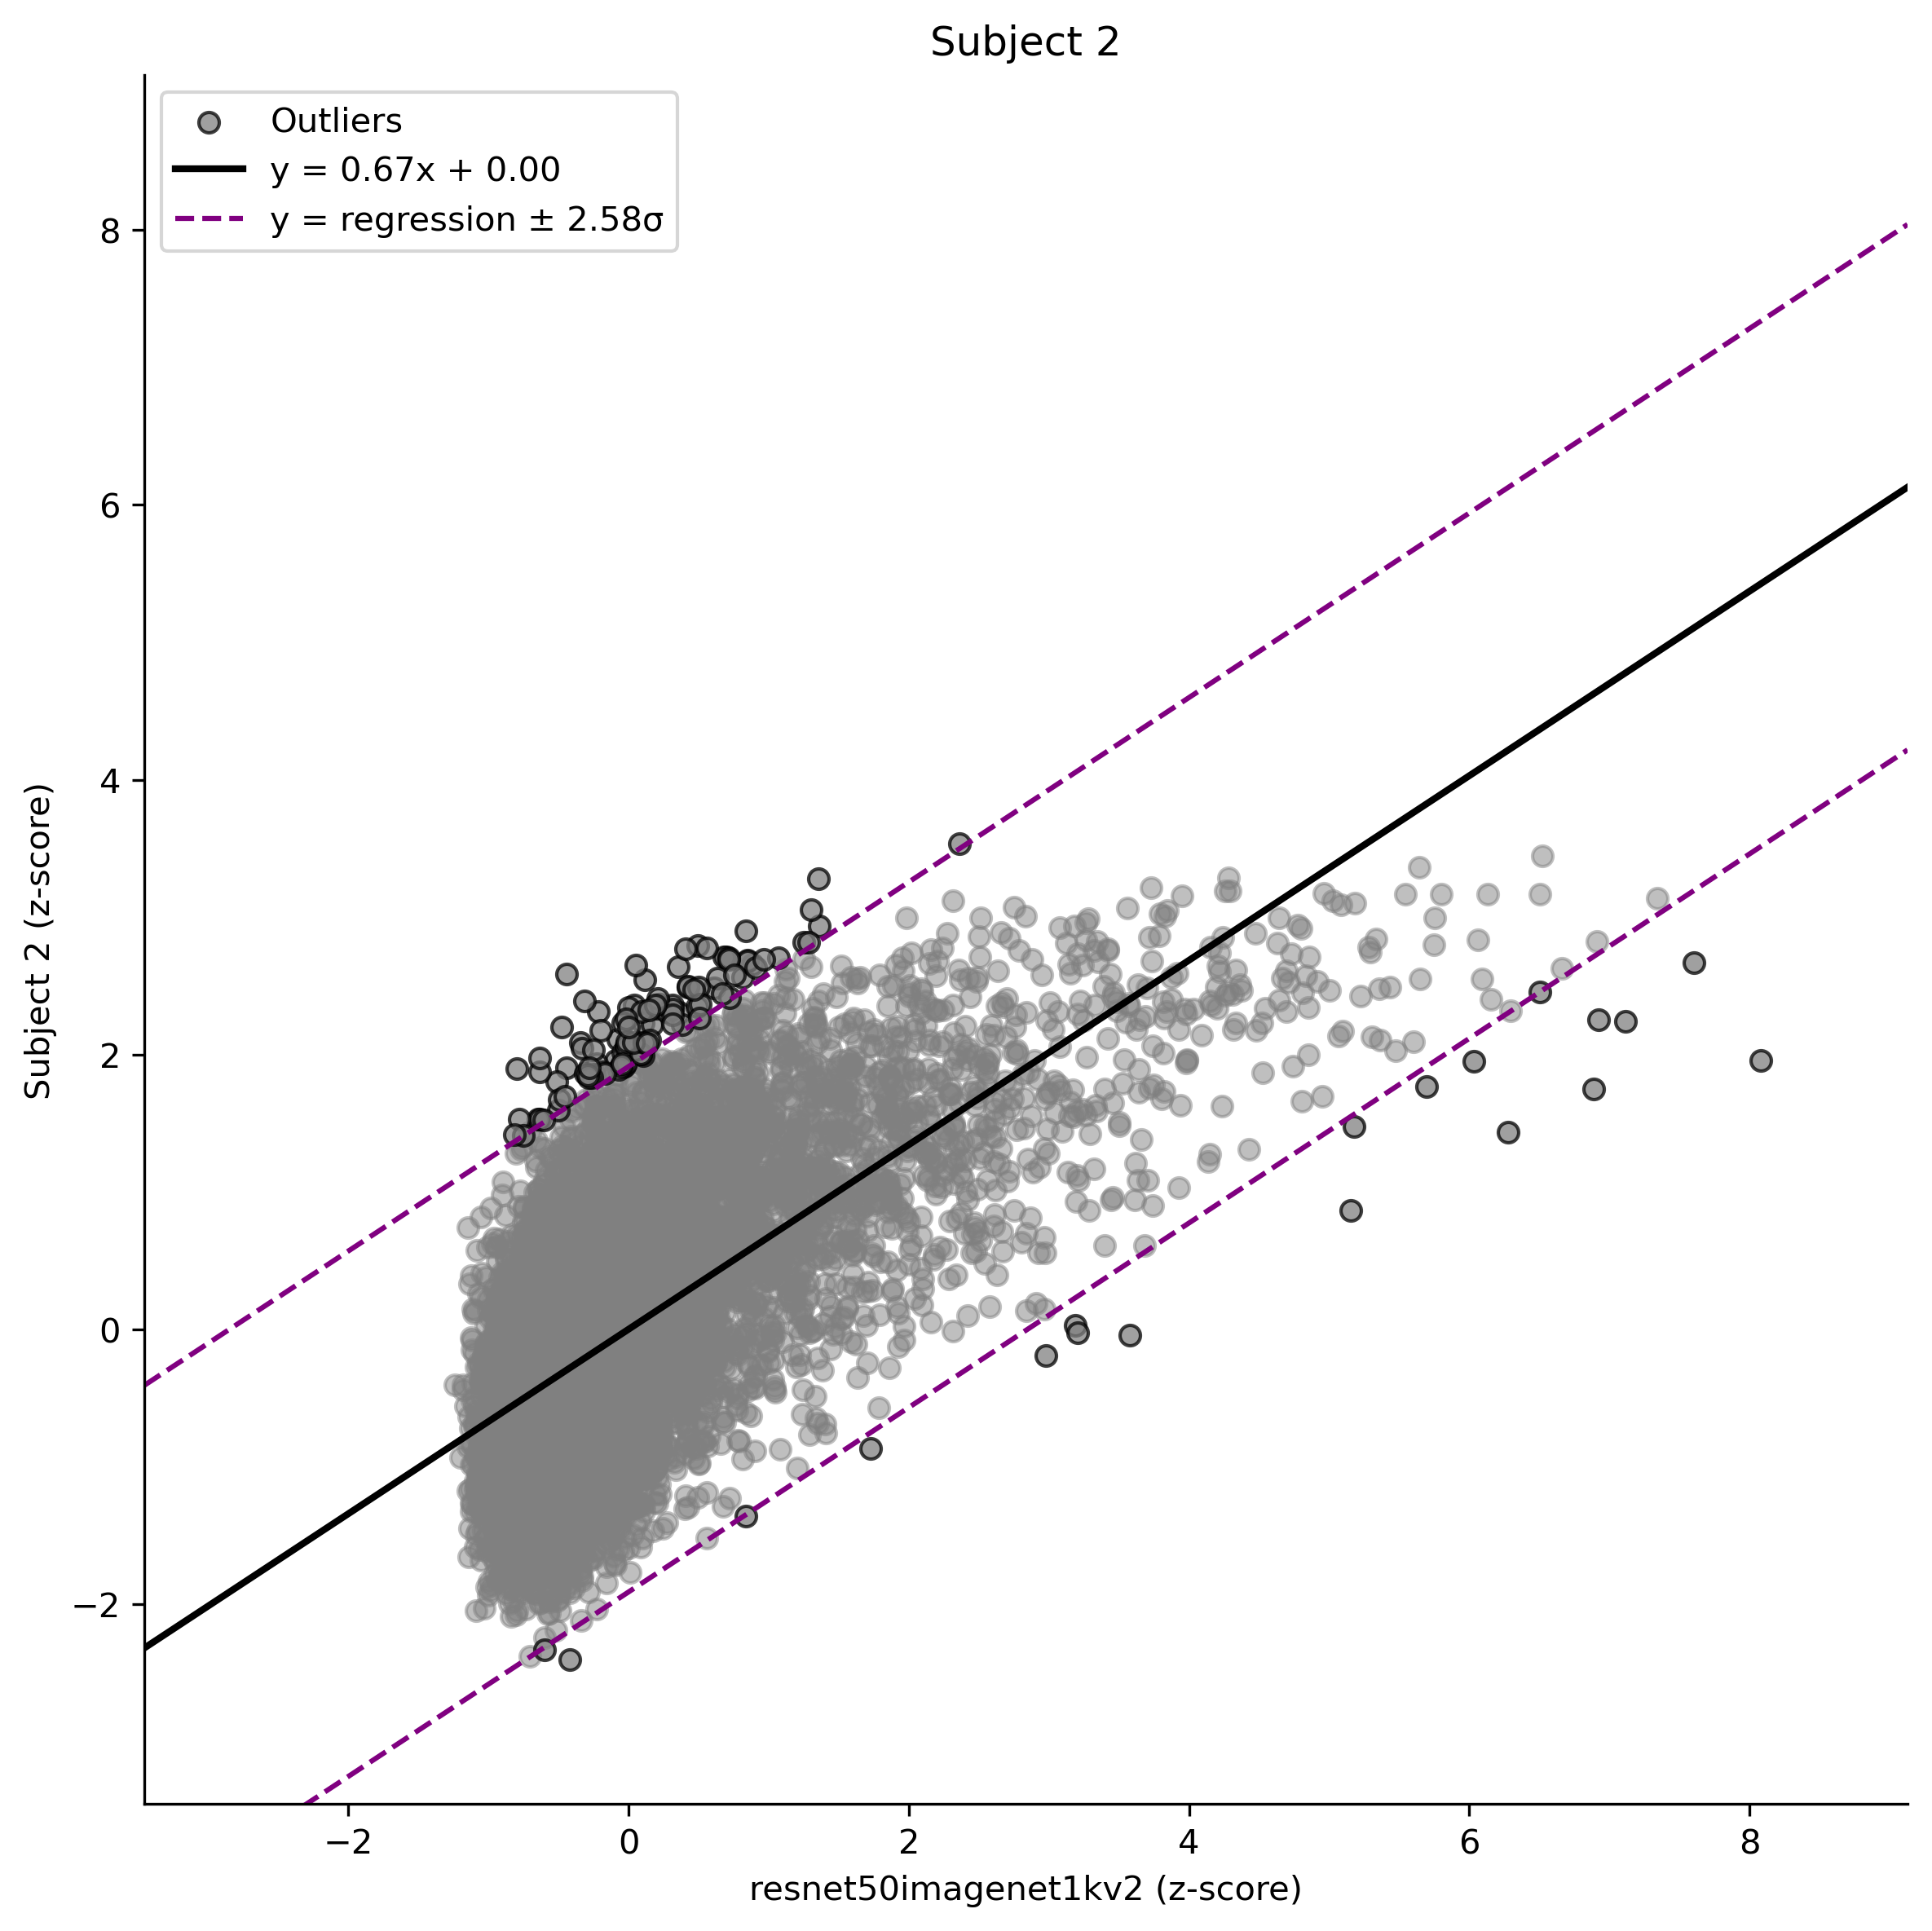

In [ ]:
# Schematic
subject = 2
fig, axes = plt.subplots(1, 1, figsize=(8, 8), dpi=300)

# Get subject data
subject_data, subject_stim_map = nsd.get_betas(
    paths.NSD_DIR, subject, froi=froi, tthreshold=tthreshold, voxels=False, repetition_mean=True
)
# Filter out nsdIds that are in stim1000_nsdids
subject_stim_map_9000 = subject_stim_map[~subject_stim_map['nsdId'].isin(stim1000_nsdids)]
subject_data_9000 = subject_data[~subject_stim_map['nsdId'].isin(stim1000_nsdids)]
# Add labels
subject_stim_map_9000_labels = add_image_labels_to_df(subject_stim_map_9000)

# Get model data
model_subject_data_9000 = model_allnsdstim_activations.mean(axis=-1)[list(subject_stim_map_9000['nsdId'])]

# Normalize the data
normalized_model_data = z_score_normalize(model_subject_data_9000)
normalized_subject_data = z_score_normalize(subject_data_9000)
X = normalized_model_data.numpy()
y = normalized_subject_data.numpy()

# Fit the model using statsmodels (now with intercept)
X_with_intercept = sm.add_constant(X)
ols_model = sm.OLS(y, X_with_intercept).fit()
slope = ols_model.params[1].item()
intercept = ols_model.params[0].item()

# Parameters
standardized_residual_threshold = 2.58
n = len(X)  # number of data points
k = 1   # number of predictors
# Degrees of freedom
df = n - k - 1

# Standardized residuals
standardized_residuals = ols_model.get_influence().resid_studentized_internal
outliers = np.abs(standardized_residuals) > standardized_residual_threshold

# Regression line with intercept
regression_line = slope * X + intercept
pearson_rho = np.corrcoef(X, y)[0, 1]

# Calculate prediction bounds based on standardized residuals
residual_std = np.std(y - regression_line)
upper_bound = standardized_residual_threshold * residual_std
lower_bound = -standardized_residual_threshold * residual_std

# Plot scatter points in the corresponding subplot
ax = axes
ax.scatter(normalized_model_data[~outliers], normalized_subject_data[~outliers], alpha=0.5, color='gray')
ax.scatter(normalized_model_data[outliers], normalized_subject_data[outliers], alpha=0.75, color='gray', edgecolors='white', label='Outliers')

# Set equal axes limits
axis_min = min(normalized_model_data.min().item(), normalized_subject_data.min().item())
axis_max = max(normalized_model_data.max().item(), normalized_subject_data.max().item())
margin = 0.1 * (axis_max - axis_min)
ax.set_xlim(axis_min - margin, axis_max + margin)
ax.set_ylim(axis_min - margin, axis_max + margin)

# Get the actual axis limits for line plotting
x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()
x_vals = np.linspace(x_min, x_max, 100)

# Plot regression line with intercept
ax.plot(x_vals, slope * x_vals + intercept, color='k', linewidth=2, 
    label=f'y = {slope:.2f}x + {intercept:.2f}')

# Plot bounds based on standardized residual threshold
ax.plot(x_vals, slope * x_vals + intercept + upper_bound, color='purple', linestyle='--', 
        label=f"y = regression ± {standardized_residual_threshold:.2f}σ")
ax.plot(x_vals, slope * x_vals + intercept + lower_bound, color='purple', linestyle='--')

ax.set_title(f'Subject {subject}')
ax.set_xlabel(f'{test_model_name} (z-score)')
ax.set_ylabel(f'Subject {subject} (z-score)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# ax.legend()
# Add Pearson correlation to bottom right corner
ax.text(0.95, 0.05, rf'$\rho$ = {pearson_rho:.2f}', 
    horizontalalignment='right', 
    verticalalignment='bottom', 
    transform=ax.transAxes, 
    fontsize=12, 
    bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

# Make background transparent
fig.patch.set_alpha(0)

plt.tight_layout()
plt.savefig('results/plots/schematic/subject_model_9000_schematic.png', dpi=300, bbox_inches='tight', transparent=True)
# plt.show()

## Std outliers

P-value: 0.0500


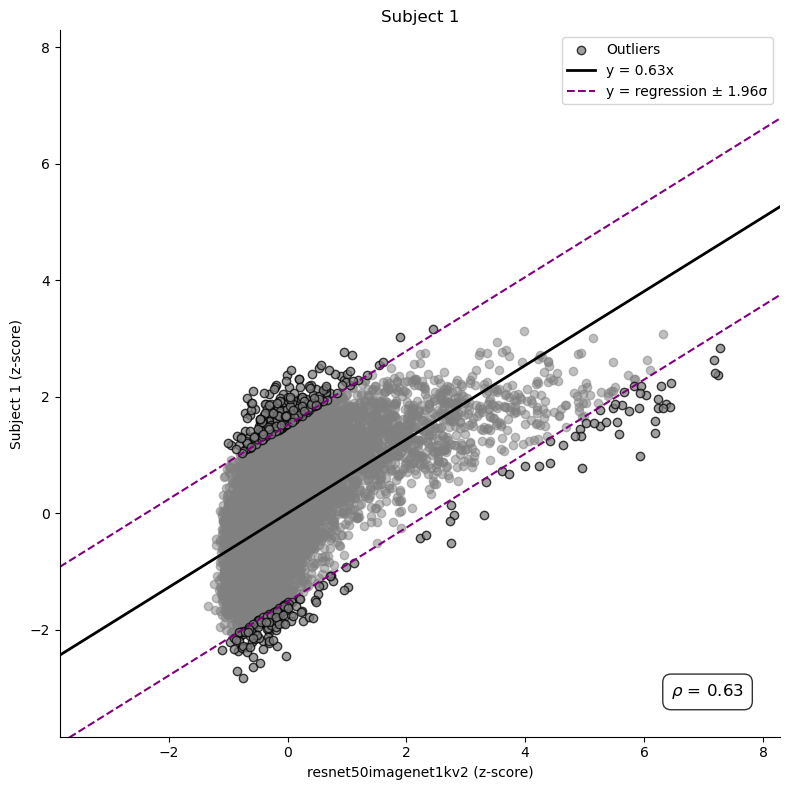

In [4]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))

subject = 1
s1_outliers_dict = {}

# Get subject data
subject_data, subject_stim_map = nsd.get_betas(
    paths.NSD_DIR, subject, froi=froi, tthreshold=tthreshold, voxels=False, repetition_mean=True
)
# Get model data
model_subject_data = model_allnsdstim_activations.mean(axis=-1)[subject_stim_map['nsdId']]

# Normalize the data
normalized_model_data = z_score_normalize(model_subject_data)
normalized_subject_data = z_score_normalize(subject_data)
X = normalized_model_data.numpy()
y = normalized_subject_data.numpy()

# Fit the model using statsmodels
X_with_intercept = sm.add_constant(X)
ols_model = sm.OLS(y, X).fit()
slope = ols_model.params[0].item()

# Parameters
standardized_residual_threshold = 1.96
n = len(X)  # number of data points
k = 1   # number of predictors
# Degrees of freedom
df = n - k - 1
# Two-tailed p-value
p_value = 2 * (1 - stats.t.cdf(standardized_residual_threshold, df))
print(f"P-value: {p_value:.4f}")

# Standardized residuals
standardized_residuals = ols_model.get_influence().resid_studentized_internal
outliers = np.abs(standardized_residuals) > standardized_residual_threshold

# Regression line
regression_line = slope * X
pearson_rho = np.corrcoef(X, y)[0, 1]

# Calculate prediction bounds based on standardized residuals
residual_std = np.std(y - regression_line)
upper_bound = standardized_residual_threshold * residual_std
lower_bound = -standardized_residual_threshold * residual_std

subject_model_outliers = standardized_residuals > standardized_residual_threshold
model_subject_outliers = standardized_residuals < -standardized_residual_threshold
s1_outliers_dict[subject] = {
    'all_outliers': outliers,
    'subject>model': subject_model_outliers,
    'model>subject': model_subject_outliers,
    'subject_normed_responses': y,
    'model_normed_responses': X,
    'slope': slope,
    'pearson_rho': pearson_rho,
    'nsdid_map': subject_stim_map
}

# Plot scatter points
ax.scatter(normalized_model_data[~outliers], normalized_subject_data[~outliers], alpha=0.5, color='gray')
ax.scatter(normalized_model_data[outliers], normalized_subject_data[outliers], alpha=0.75, color='gray', edgecolors='black', label='Outliers')

# Set equal axes limits
axis_min = min(normalized_model_data.min().item(), normalized_subject_data.min().item())
axis_max = max(normalized_model_data.max().item(), normalized_subject_data.max().item())
margin = 0.1 * (axis_max - axis_min)
ax.set_xlim(axis_min - margin, axis_max + margin)
ax.set_ylim(axis_min - margin, axis_max + margin)

# Get the actual axis limits for line plotting
x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()
x_vals = np.linspace(x_min, x_max, 100)

# Plot regression line
ax.plot(x_vals, slope * x_vals, color='k', linewidth=2, 
    label=f'y = {slope:.2f}x')

# Plot bounds based on standardized residual threshold
ax.plot(x_vals, slope * x_vals + upper_bound, color='purple', linestyle='--', 
        label=f"y = regression ± {standardized_residual_threshold:.2f}σ")
ax.plot(x_vals, slope * x_vals + lower_bound, color='purple', linestyle='--')

ax.set_title(f'Subject {subject}')
ax.set_xlabel(f'{test_model_name} (z-score)')
ax.set_ylabel(f'Subject {subject} (z-score)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend()

# Add Pearson correlation to bottom right corner
ax.text(0.95, 0.05, rf'$\rho$ = {pearson_rho:.2f}', 
    horizontalalignment='right', 
    verticalalignment='bottom', 
    transform=ax.transAxes, 
    fontsize=12, 
    bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

plt.tight_layout()
plt.show()

P-value: 0.0500
P-value: 0.0500
P-value: 0.0500
P-value: 0.0500


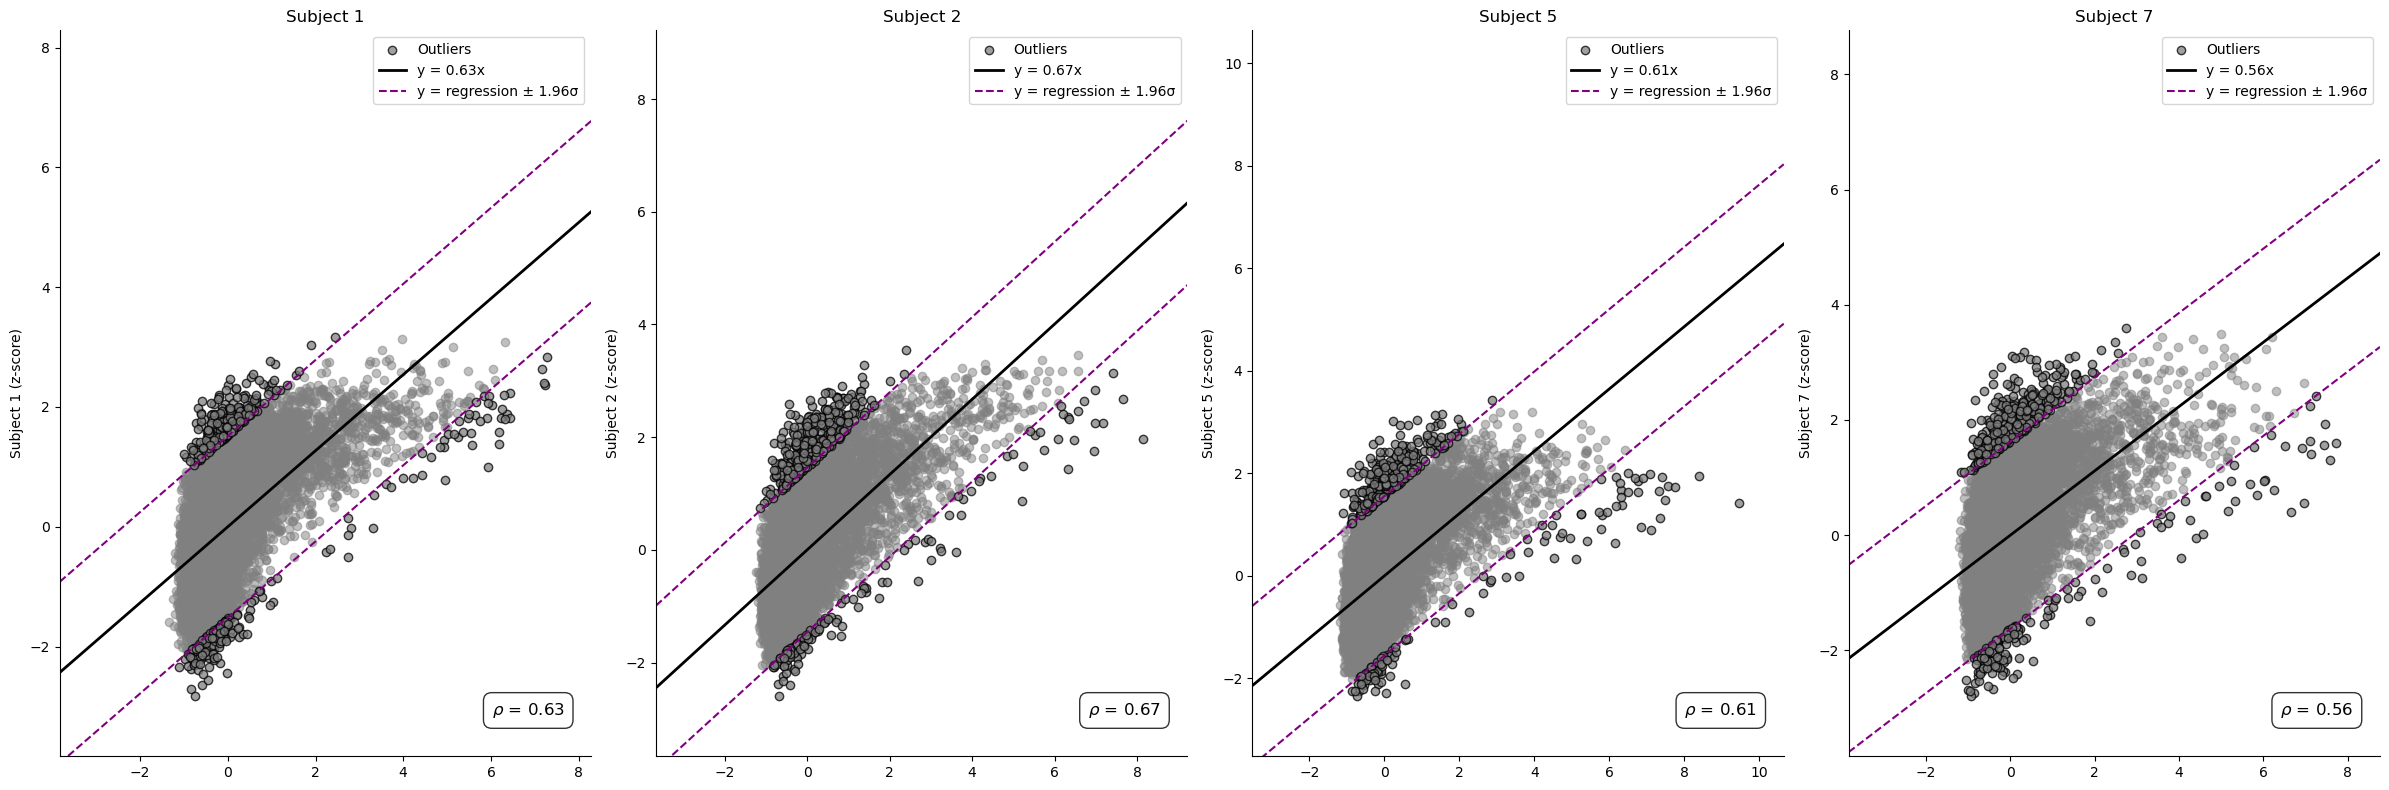

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(24, 8))
standardized_residual_threshold = 1.96
outliers_dict = {}

for ax_idx, subject in enumerate(train_subjects):
    ax = axes[ax_idx]
    # Get subject data
    subject_data, subject_stim_map = nsd.get_betas(
        paths.NSD_DIR, subject, froi=froi, tthreshold=tthreshold, voxels=False, repetition_mean=True
    )
    # Get model data
    model_subject_data = model_allnsdstim_activations.mean(axis=-1)[subject_stim_map['nsdId']]

    # Normalize the data
    normalized_model_data = z_score_normalize(model_subject_data)
    normalized_subject_data = z_score_normalize(subject_data)
    X = normalized_model_data.numpy()
    y = normalized_subject_data.numpy()

    # Fit the model using statsmodels
    X_with_intercept = sm.add_constant(X)
    ols_model = sm.OLS(y, X).fit()
    slope = ols_model.params[0].item()

    # Parameters
    n = len(X)  # number of data points
    k = 1   # number of predictors
    # Degrees of freedom
    df = n - k - 1
    # Two-tailed p-value
    p_value = 2 * (1 - stats.t.cdf(standardized_residual_threshold, df))
    print(f"P-value: {p_value:.4f}")

    # Standardized residuals
    standardized_residuals = ols_model.get_influence().resid_studentized_internal
    outliers = np.abs(standardized_residuals) > standardized_residual_threshold

    # Regression line
    regression_line = slope * X
    pearson_rho = np.corrcoef(X, y)[0, 1]

    # Calculate prediction bounds based on standardized residuals
    residual_std = np.std(y - regression_line)
    upper_bound = standardized_residual_threshold * residual_std
    lower_bound = -standardized_residual_threshold * residual_std

    # Store outliers data
    subject_model_outliers = standardized_residuals > standardized_residual_threshold
    model_subject_outliers = standardized_residuals < -standardized_residual_threshold
    outliers_dict[subject] = {
        'all_outliers': outliers,
        'subject>model': subject_model_outliers,
        'model>subject': model_subject_outliers,
        'subject_normed_responses': y,
        'model_normed_responses': X,
        'slope': slope,
        'pearson_rho': pearson_rho,
        'nsdid_map': subject_stim_map
    }

    # Plot scatter points
    ax.scatter(normalized_model_data[~outliers], normalized_subject_data[~outliers], alpha=0.5, color='gray')
    ax.scatter(normalized_model_data[outliers], normalized_subject_data[outliers], alpha=0.75, color='gray', edgecolors='black', label='Outliers')

    # Set equal axes limits
    axis_min = min(normalized_model_data.min().item(), normalized_subject_data.min().item())
    axis_max = max(normalized_model_data.max().item(), normalized_subject_data.max().item())
    margin = 0.1 * (axis_max - axis_min)
    ax.set_xlim(axis_min - margin, axis_max + margin)
    ax.set_ylim(axis_min - margin, axis_max + margin)

    # Get the actual axis limits for line plotting
    x_min, x_max = ax.get_xlim()
    y_min, y_max = ax.get_ylim()
    x_vals = np.linspace(x_min, x_max, 100)

    # Plot regression line
    ax.plot(x_vals, slope * x_vals, color='k', linewidth=2, 
        label=f'y = {slope:.2f}x')

    # Plot bounds based on standardized residual threshold
    ax.plot(x_vals, slope * x_vals + upper_bound, color='purple', linestyle='--', 
            label=f"y = regression ± {standardized_residual_threshold:.2f}σ")
    ax.plot(x_vals, slope * x_vals + lower_bound, color='purple', linestyle='--')

    ax.set_title(f'Subject {subject}')
    # ax.set_xlabel(f'{model_utils.get_model_name(model)} (z-score)')
    ax.set_ylabel(f'Subject {subject} (z-score)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.legend()

    # Add Pearson correlation to bottom right corner
    ax.text(0.95, 0.05, rf'$\rho$ = {pearson_rho:.2f}', 
        horizontalalignment='right',
        verticalalignment='bottom',
        transform=ax.transAxes,
        fontsize=12,
        bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

plt.tight_layout()
plt.show()

# Std outliers with intercept

P-value: 0.0500


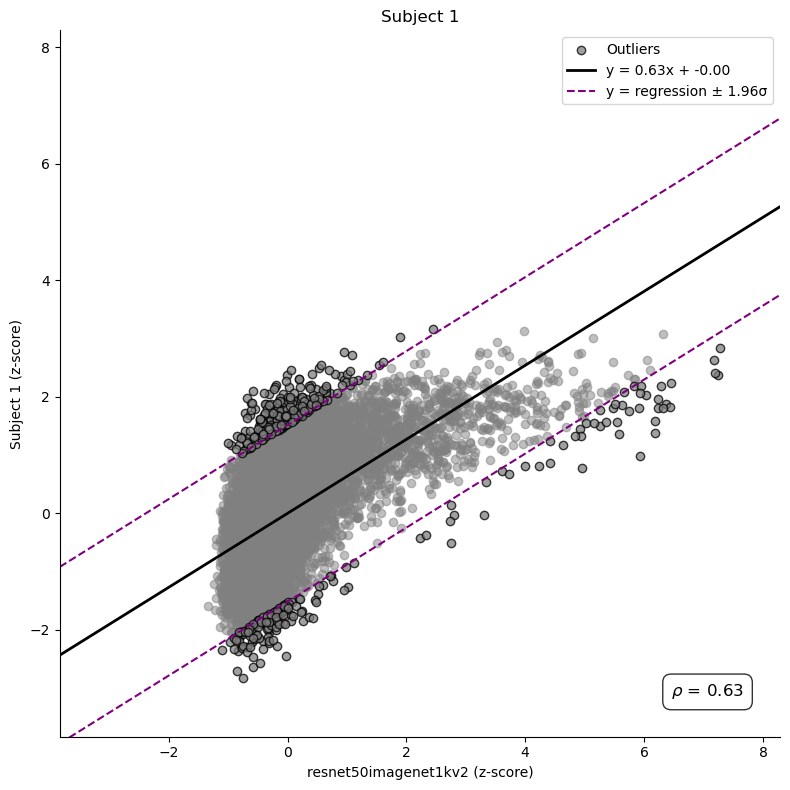

In [62]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))

subject = 1
s1_outliers_dict = {}

# Get subject data
subject_data, subject_stim_map = nsd.get_betas(
    paths.NSD_DIR, subject, froi=froi, tthreshold=tthreshold, voxels=False, repetition_mean=True
)
# Get model data
model_subject_data = model_allnsdstim_activations.mean(axis=-1)[subject_stim_map['nsdId']]

# Normalize the data
normalized_model_data = z_score_normalize(model_subject_data)
normalized_subject_data = z_score_normalize(subject_data)
X = normalized_model_data.numpy()
y = normalized_subject_data.numpy()

# Fit the model using statsmodels (now with intercept)
X_with_intercept = sm.add_constant(X)
ols_model = sm.OLS(y, X_with_intercept).fit()
slope = ols_model.params[1].item()
intercept = ols_model.params[0].item()

# Parameters
standardized_residual_threshold = 1.96
n = len(X)  # number of data points
k = 1   # number of predictors
# Degrees of freedom
df = n - k - 1
# Two-tailed p-value
p_value = 2 * (1 - stats.t.cdf(standardized_residual_threshold, df))
print(f"P-value: {p_value:.4f}")

# Standardized residuals
standardized_residuals = ols_model.get_influence().resid_studentized_internal
outliers = np.abs(standardized_residuals) > standardized_residual_threshold

# Regression line with intercept
regression_line = slope * X + intercept
pearson_rho = np.corrcoef(X, y)[0, 1]

# Calculate prediction bounds based on standardized residuals
residual_std = np.std(y - regression_line)
upper_bound = standardized_residual_threshold * residual_std
lower_bound = -standardized_residual_threshold * residual_std

subject_model_outliers = standardized_residuals > standardized_residual_threshold
model_subject_outliers = standardized_residuals < -standardized_residual_threshold
s1_outliers_dict[subject] = {
    'all_outliers': outliers,
    'subject>model': subject_model_outliers,
    'model>subject': model_subject_outliers,
    'subject_normed_responses': y,
    'model_normed_responses': X,
    'slope': slope,
    'intercept': intercept,
    'pearson_rho': pearson_rho,
    'nsdid_map': subject_stim_map
}

# Plot scatter points
ax.scatter(normalized_model_data[~outliers], normalized_subject_data[~outliers], alpha=0.5, color='gray')
ax.scatter(normalized_model_data[outliers], normalized_subject_data[outliers], alpha=0.75, color='gray', edgecolors='black', label='Outliers')

# Set equal axes limits
axis_min = min(normalized_model_data.min().item(), normalized_subject_data.min().item())
axis_max = max(normalized_model_data.max().item(), normalized_subject_data.max().item())
margin = 0.1 * (axis_max - axis_min)
ax.set_xlim(axis_min - margin, axis_max + margin)
ax.set_ylim(axis_min - margin, axis_max + margin)

# Get the actual axis limits for line plotting
x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()
x_vals = np.linspace(x_min, x_max, 100)

# Plot regression line with intercept
ax.plot(x_vals, slope * x_vals + intercept, color='k', linewidth=2, 
    label=f'y = {slope:.2f}x + {intercept:.2f}')

# Plot bounds based on standardized residual threshold
ax.plot(x_vals, slope * x_vals + intercept + upper_bound, color='purple', linestyle='--', 
        label=f"y = regression ± {standardized_residual_threshold:.2f}σ")
ax.plot(x_vals, slope * x_vals + intercept + lower_bound, color='purple', linestyle='--')

ax.set_title(f'Subject {subject}')
ax.set_xlabel(f'{test_model_name} (z-score)')
ax.set_ylabel(f'Subject {subject} (z-score)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend()

# Add Pearson correlation to bottom right corner
ax.text(0.95, 0.05, rf'$\rho$ = {pearson_rho:.2f}', 
    horizontalalignment='right', 
    verticalalignment='bottom', 
    transform=ax.transAxes, 
    fontsize=12, 
    bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

plt.tight_layout()
plt.show()

## Piecewise linear regression

In [ ]:
subject = 1
s1_outliers_dict = {}

# Get subject data
subject_data, subject_stim_map = nsd.get_betas(
    paths.NSD_DIR, subject, froi=froi, tthreshold=tthreshold, voxels=False, repetition_mean=True
)
# Get model data
model_subject_data = model_allnsdstim_activations.mean(axis=-1)[subject_stim_map['nsdId']]

# Normalize the data
normalized_model_data = z_score_normalize(model_subject_data)
normalized_subject_data = z_score_normalize(subject_data)
X = normalized_model_data.numpy()
y = normalized_subject_data.numpy()

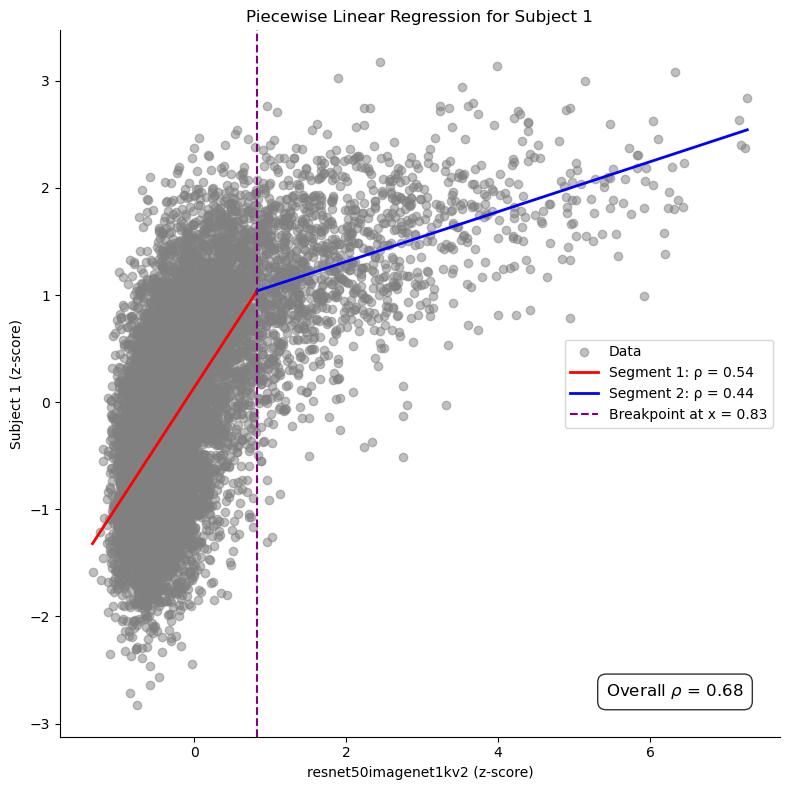

Breakpoints: [-1.33944666  0.82650059  7.2770772 ]
Overall Pearson Correlation: 0.6844
Segment 1 Pearson Correlation: 0.5355
Segment 2 Pearson Correlation: 0.4382
Number of points in Segment 1: 8713
Number of points in Segment 2: 1287
Slope for Segment 1: 1.0890
Slope for Segment 2: 0.2330


In [74]:
from scipy import stats
import numpy as np

import matplotlib.pyplot as plt
import pwlf  # Make sure pwlf is installed

fig, ax = plt.subplots(1, 1, figsize=(8, 8))

# Fit piecewise linear model with 2 segments
model = pwlf.PiecewiseLinFit(X, y)
breaks = model.fit(2)

# Get the predicted values
y_pred = model.predict(X)

# Calculate overall Pearson correlation coefficient
corr, _ = stats.pearsonr(y, y_pred)

# Sort the data by X for easier segmentation
sorted_indices = np.argsort(X)
X_sorted = X[sorted_indices]
y_sorted = y[sorted_indices]

# Get the segment locations
segment_indices = []
for i, x_val in enumerate(X_sorted):
    if x_val >= breaks[1]:  # First breakpoint after the minimum x value
        segment_indices.append(i)
        break

# Calculate Pearson for each segment
segment1_X = X_sorted[:segment_indices[0]]
segment1_y = y_sorted[:segment_indices[0]]
segment1_y_pred = model.predict(segment1_X)
corr1, _ = stats.pearsonr(segment1_y, segment1_y_pred)

segment2_X = X_sorted[segment_indices[0]:]
segment2_y = y_sorted[segment_indices[0]:]
segment2_y_pred = model.predict(segment2_X)
corr2, _ = stats.pearsonr(segment2_y, segment2_y_pred)

# Plot the data and piecewise regression
ax.scatter(X, y, alpha=0.5, color='gray', label="Data")

# Get X values for plotting smooth lines
X_for_plot = np.linspace(X.min(), X.max(), 1000)
y_for_plot = model.predict(X_for_plot)

# Find the indices where the line breaks
break_indices = []
for i in range(len(X_for_plot) - 1):
    if (X_for_plot[i] <= breaks[1] and X_for_plot[i+1] > breaks[1]):
        break_indices.append(i)

# Plot the piecewise linear fit
ax.plot(X_for_plot[:break_indices[0]+1], y_for_plot[:break_indices[0]+1], 'r-', 
        linewidth=2, label=f"Segment 1: ρ = {corr1:.2f}")
ax.plot(X_for_plot[break_indices[0]:], y_for_plot[break_indices[0]:], 'b-', 
        linewidth=2, label=f"Segment 2: ρ = {corr2:.2f}")

# Mark the breakpoint
ax.axvline(x=breaks[1], color='purple', linestyle='--', 
           label=f"Breakpoint at x = {breaks[1]:.2f}")

ax.set_title(f'Piecewise Linear Regression for Subject {subject}')
ax.set_xlabel(f'{test_model_name} (z-score)')
ax.set_ylabel(f'Subject {subject} (z-score)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend()

# Add overall Pearson correlation to bottom right corner
ax.text(0.95, 0.05, rf'Overall $\rho$ = {corr:.2f}', 
    horizontalalignment='right', 
    verticalalignment='bottom', 
    transform=ax.transAxes, 
    fontsize=12, 
    bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

plt.tight_layout()
plt.show()

# Print the statistics
print(f"Breakpoints: {breaks}")
print(f"Overall Pearson Correlation: {corr:.4f}")
print(f"Segment 1 Pearson Correlation: {corr1:.4f}")
print(f"Segment 2 Pearson Correlation: {corr2:.4f}")
print(f"Number of points in Segment 1: {len(segment1_X)}")
print(f"Number of points in Segment 2: {len(segment2_X)}")

# Calculate and print the slopes for each segment
slopes = model.calc_slopes()
print(f"Slope for Segment 1: {slopes[0]:.4f}")
print(f"Slope for Segment 2: {slopes[1]:.4f}")

## Clustering

In [24]:
subject = 1

# Get subject data
subject_data, subject_stim_map = nsd.get_betas(
    paths.NSD_DIR, subject, froi=froi, tthreshold=tthreshold, voxels=False, repetition_mean=True
)
# Get model data
model_subject_data = model_allnsdstim_activations.mean(axis=-1)[subject_stim_map['nsdId']]

# Normalize the data
normalized_model_data = z_score_normalize(model_subject_data)
normalized_subject_data = z_score_normalize(subject_data)
X = normalized_model_data.numpy()
y = normalized_subject_data.numpy()

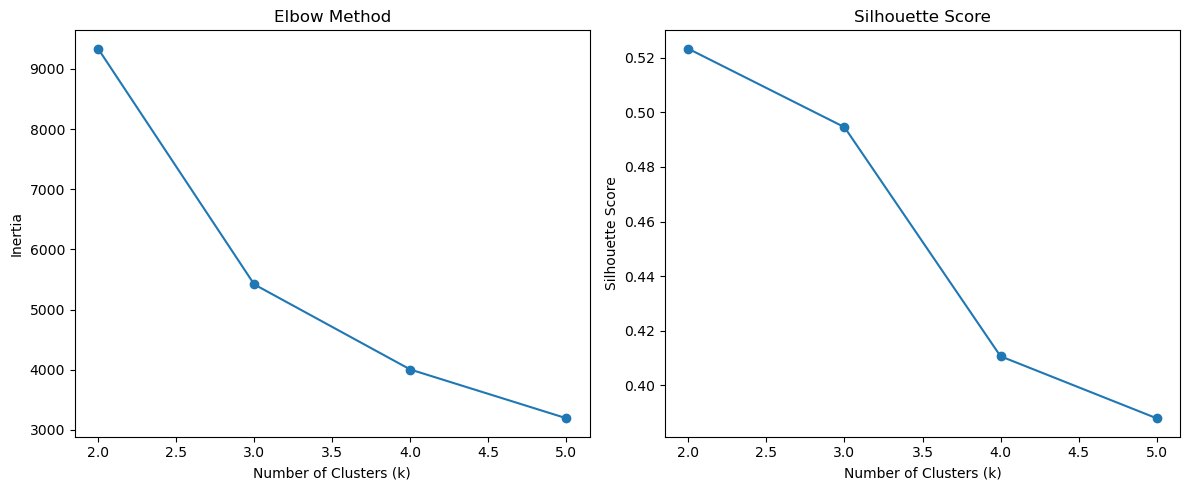

Optimal k (Elbow Method): 3
Optimal k (Silhouette Score): 2


In [25]:
data = np.vstack((X, y)).T
# Parameters
max_clusters = 5  # Test clusters from 2 to 15
inertia = []
silhouette_scores = []

# Run K-means for different cluster sizes
for k in range(2, max_clusters + 1):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(data)
    
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(data, kmeans.labels_))

# Plot Elbow Method
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(range(2, max_clusters + 1), inertia, marker='o')
ax[0].set_title('Elbow Method')
ax[0].set_xlabel('Number of Clusters (k)')
ax[0].set_ylabel('Inertia')

# Plot Silhouette Score
ax[1].plot(range(2, max_clusters + 1), silhouette_scores, marker='o')
ax[1].set_title('Silhouette Score')
ax[1].set_xlabel('Number of Clusters (k)')
ax[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

# Automatically select optimal clusters
optimal_k_elbow = np.argmin(np.diff(np.diff(inertia))) + 2
optimal_k_silhouette = np.argmax(silhouette_scores) + 2

print(f"Optimal k (Elbow Method): {optimal_k_elbow}")
print(f"Optimal k (Silhouette Score): {optimal_k_silhouette}")

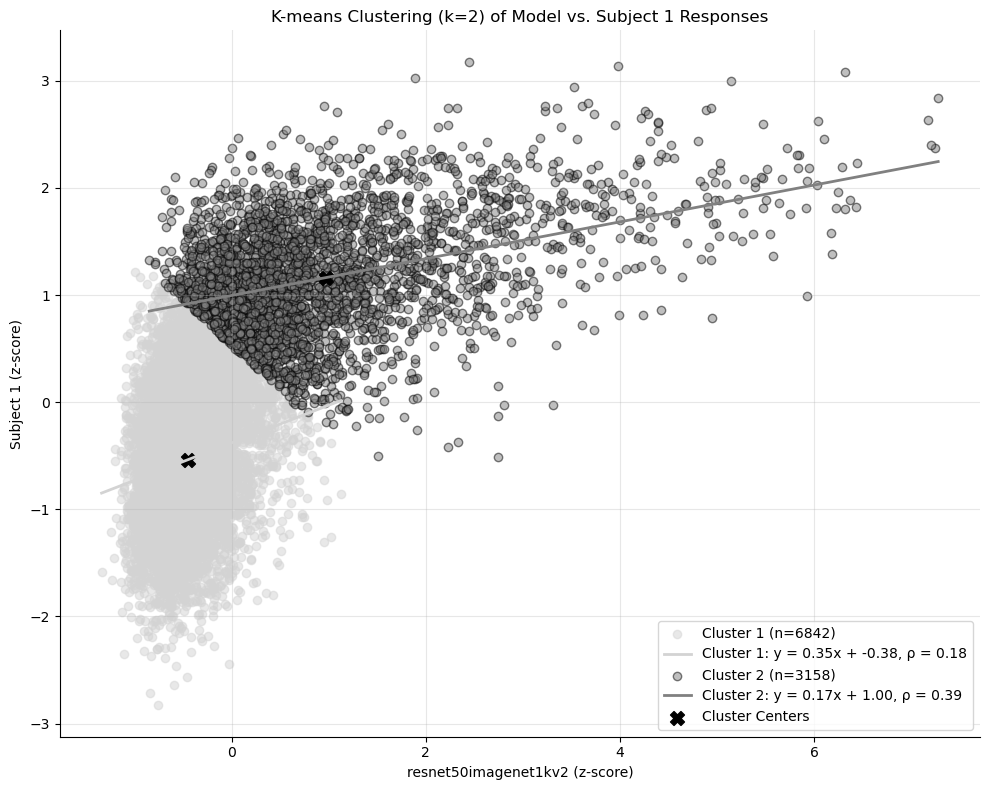

Overall: y = 0.63x + -0.00, Pearson ρ = 0.6349
Cluster 1: 6842 points, y = 0.35x + -0.38, Pearson ρ = 0.1827
Cluster 2: 3158 points, y = 0.17x + 1.00, Pearson ρ = 0.3900


In [27]:
# Apply K-means clustering with optimal k=2
k = 2
kmeans = KMeans(n_clusters=k, random_state=SEED, n_init='auto', max_iter=500)
cluster_labels = kmeans.fit_predict(data)

# Create a scatter plot with different colors for each cluster
fig, ax = plt.subplots(figsize=(10, 8))

# Define colors for the clusters
colors = ['lightgray', 'gray']
cluster_names = ['Cluster 1', 'Cluster 2']
outlier_cluster = 1 # Cluster with outliers

# Plot each cluster with a different color
for i in range(k):
    cluster_mask = cluster_labels == i
    if i == outlier_cluster:
        ax.scatter(X[cluster_mask], y[cluster_mask], 
                c=colors[i], alpha=0.5, label=f'{cluster_names[i]} (n={np.sum(cluster_mask)})', edgecolors='black')
    else:
        ax.scatter(X[cluster_mask], y[cluster_mask], 
                c=colors[i], alpha=0.5, label=f'{cluster_names[i]} (n={np.sum(cluster_mask)})')
    
    # Fit regression line for this cluster
    if np.sum(cluster_mask) > 1:  # Make sure we have at least 2 points for correlation
        X_cluster = X[cluster_mask]
        y_cluster = y[cluster_mask]
        
        # Fit OLS model with intercept
        X_cluster_with_intercept = sm.add_constant(X_cluster)
        ols_model = sm.OLS(y_cluster, X_cluster_with_intercept).fit()
        slope = ols_model.params[1].item()
        intercept = ols_model.params[0].item()
        
        # Calculate Pearson correlation
        pearson_rho = np.corrcoef(X_cluster, y_cluster)[0, 1]
        
        # Plot regression line
        x_range = np.linspace(X_cluster.min(), X_cluster.max(), 100)
        ax.plot(x_range, slope * x_range + intercept, 
                color=colors[i], linewidth=2, 
                label=f'{cluster_names[i]}: y = {slope:.2f}x + {intercept:.2f}, ρ = {pearson_rho:.2f}')

# Plot the cluster centers
ax.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], 
           c='black', marker='X', s=100, label='Cluster Centers')

# Set labels and title
ax.set_xlabel(f'{test_model_name} (z-score)')
ax.set_ylabel(f'Subject {subject} (z-score)')
ax.set_title(f'K-means Clustering (k={k}) of Model vs. Subject {subject} Responses')

# Add legend and grid
ax.legend()
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# Calculate overall statistics
X_with_intercept = sm.add_constant(X)
overall_model = sm.OLS(y, X_with_intercept).fit()
overall_slope = overall_model.params[1].item()
overall_intercept = overall_model.params[0].item()
overall_rho = np.corrcoef(X, y)[0, 1]
print(f"Overall: y = {overall_slope:.2f}x + {overall_intercept:.2f}, Pearson ρ = {overall_rho:.4f}")

# Print cluster statistics
for i in range(k):
    cluster_mask = cluster_labels == i
    X_cluster = X[cluster_mask]
    y_cluster = y[cluster_mask]
    
    if np.sum(cluster_mask) > 1:
        X_cluster_with_intercept = sm.add_constant(X_cluster)
        ols_model = sm.OLS(y_cluster, X_cluster_with_intercept).fit()
        slope = ols_model.params[1].item()
        intercept = ols_model.params[0].item()
        cluster_pearson = np.corrcoef(X_cluster, y_cluster)[0, 1]
        cluster_size = np.sum(cluster_mask)
        print(f"{cluster_names[i]}: {cluster_size} points, y = {slope:.2f}x + {intercept:.2f}, Pearson ρ = {cluster_pearson:.4f}")

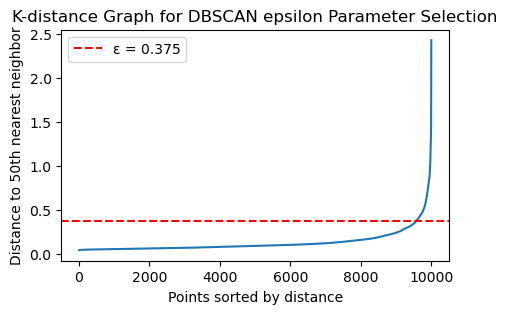

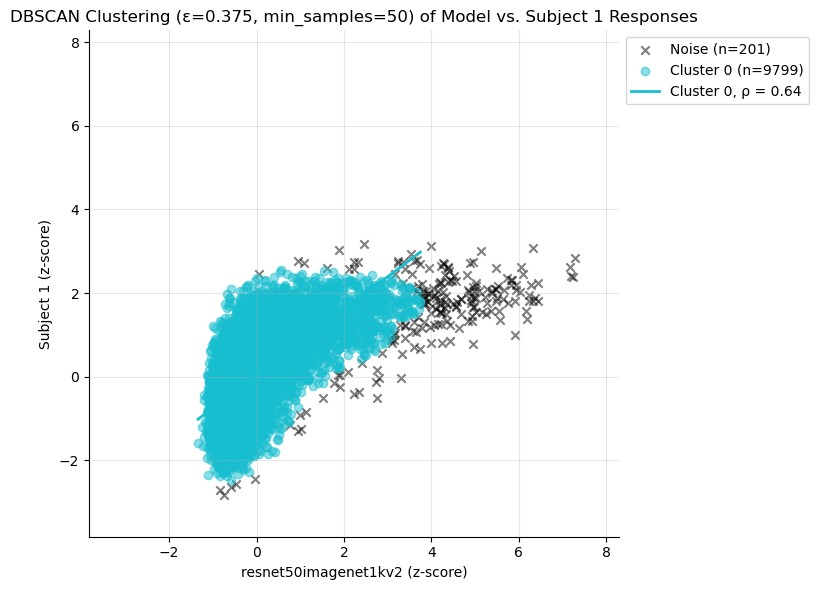

Overall: y = 0.63x + -0.00, Pearson ρ = 0.6349
Noise points: 201
Cluster 0: 9799 points, y = 0.79x + 0.03, Pearson ρ = 0.6398


In [58]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import numpy as np

# Apply DBSCAN clustering
import matplotlib.pyplot as plt

# First determine optimal epsilon parameter using nearest neighbors
k = 50  # Number of neighbors to consider
nn = NearestNeighbors(n_neighbors=k)
nn.fit(data)
distances, indices = nn.kneighbors(data)

# Sort distances to find the "elbow"
distances = np.sort(distances[:, k-1])
eps_candidates = np.linspace(0.2, 1.0, 9)  # Different epsilon values to try

eps = 0.375  # Based on the elbow in the distance plot

# Plot distance graph to determine epsilon
plt.figure(figsize=(5, 3))
plt.plot(range(len(distances)), distances)
plt.axhline(y=eps, color='r', linestyle='--', label=f'ε = {eps}')
plt.xlabel('Points sorted by distance')
plt.ylabel(f'Distance to {k}th nearest neighbor')
plt.title('K-distance Graph for DBSCAN epsilon Parameter Selection')
plt.legend()
plt.show()

# Apply DBSCAN with selected epsilon
min_samples = 50  # Minimum points to form a dense region
dbscan = DBSCAN(eps=eps, min_samples=min_samples)
cluster_labels = dbscan.fit_predict(data)

# Create a scatter plot with different colors for each cluster
fig, ax = plt.subplots(figsize=(8, 6))

# Get unique cluster labels
unique_labels = np.unique(cluster_labels)
# Define colors for the clusters (excluding noise points which are labeled as -1)
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_labels)))

# Plot each cluster with a different color
for i, label in enumerate(unique_labels):
    if label == -1:
        # Noise points in black
        cluster_mask = cluster_labels == label
        ax.scatter(X[cluster_mask], y[cluster_mask], 
                c='black', alpha=0.5, marker='x', label=f'Noise (n={np.sum(cluster_mask)})')
    else:
        cluster_mask = cluster_labels == label
        ax.scatter(X[cluster_mask], y[cluster_mask], 
                c=[colors[i]], alpha=0.5, label=f'Cluster {label} (n={np.sum(cluster_mask)})')
    
    # Fit regression line for this cluster (only for non-noise clusters with enough points)
    if label != -1 and np.sum(cluster_mask) > 5:
        X_cluster = X[cluster_mask]
        y_cluster = y[cluster_mask]
        
        # Fit OLS model with intercept
        X_cluster_with_intercept = sm.add_constant(X_cluster)
        ols_model = sm.OLS(y_cluster, X_cluster_with_intercept).fit()
        slope = ols_model.params[1].item()
        intercept = ols_model.params[0].item()
        
        # Calculate Pearson correlation
        pearson_rho = np.corrcoef(X_cluster, y_cluster)[0, 1]
        
        # Plot regression line
        x_range = np.linspace(X_cluster.min(), X_cluster.max(), 100)
        ax.plot(x_range, slope * x_range + intercept, 
                color=colors[i], linewidth=2, 
                label=f'Cluster {label}, ρ = {pearson_rho:.2f}')

# Set labels and title
ax.set_xlabel(f'{test_model_name} (z-score)')
ax.set_ylabel(f'Subject {subject} (z-score)')
ax.set_title(f'DBSCAN Clustering (ε={eps}, min_samples={min_samples}) of Model vs. Subject {subject} Responses')

# Set equal axes limits
axis_min = min(np.min(X), np.min(y))
axis_max = max(np.max(X), np.max(y))
margin = 0.1 * (axis_max - axis_min)
ax.set_xlim(axis_min - margin, axis_max + margin)
ax.set_ylim(axis_min - margin, axis_max + margin)

# Add legend and grid
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
ax.grid(True, alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# Calculate overall statistics
X_with_intercept = sm.add_constant(X)
overall_model = sm.OLS(y, X_with_intercept).fit()
overall_slope = overall_model.params[1].item()
overall_intercept = overall_model.params[0].item()
overall_rho = np.corrcoef(X, y)[0, 1]
print(f"Overall: y = {overall_slope:.2f}x + {overall_intercept:.2f}, Pearson ρ = {overall_rho:.4f}")

# Print cluster statistics
for label in unique_labels:
    cluster_mask = cluster_labels == label
    cluster_size = np.sum(cluster_mask)
    if label == -1:
        print(f"Noise points: {cluster_size}")
    elif cluster_size > 5:
        X_cluster = X[cluster_mask]
        y_cluster = y[cluster_mask]
        
        X_cluster_with_intercept = sm.add_constant(X_cluster)
        ols_model = sm.OLS(y_cluster, X_cluster_with_intercept).fit()
        slope = ols_model.params[1].item()
        intercept = ols_model.params[0].item()
        cluster_pearson = np.corrcoef(X_cluster, y_cluster)[0, 1]
        print(f"Cluster {label}: {cluster_size} points, y = {slope:.2f}x + {intercept:.2f}, Pearson ρ = {cluster_pearson:.4f}")

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(8, 8))

subject = 1
s1_outliers_dict = {}

# Get subject data
subject_data, subject_stim_map = nsd.get_betas(
    paths.NSD_DIR, subject, froi=froi, tthreshold=tthreshold, voxels=False, repetition_mean=True
)
# Get model data
model_subject_data = model_allnsdstim_activations.mean(axis=-1)[subject_stim_map['nsdId']]

# Normalize the data
normalized_model_data = z_score_normalize(model_subject_data)
normalized_subject_data = z_score_normalize(subject_data)
X = normalized_model_data.numpy()
y = normalized_subject_data.numpy()

# Fit the model using statsmodels
X_with_intercept = sm.add_constant(X)
model = sm.OLS(y, X).fit()
slope = model.params[0].item()

# Parameters
standardized_residual_threshold = 1.96
n = len(X)  # number of data points
k = 1   # number of predictors
# Degrees of freedom
df = n - k - 1
# Two-tailed p-value
p_value = 2 * (1 - stats.t.cdf(standardized_residual_threshold, df))
print(f"P-value: {p_value:.4f}")

# Standardized residuals
standardized_residuals = model.get_influence().resid_studentized_internal
outliers = np.abs(standardized_residuals) > standardized_residual_threshold

# Regression line
regression_line = slope * X
pearson_rho = np.corrcoef(X, y)[0, 1]

# Calculate prediction bounds based on standardized residuals
residual_std = np.std(y - regression_line)
upper_bound = standardized_residual_threshold * residual_std
lower_bound = -standardized_residual_threshold * residual_std

subject_model_outliers = standardized_residuals > standardized_residual_threshold
model_subject_outliers = standardized_residuals < -standardized_residual_threshold
s1_outliers_dict[subject] = {
    'all_outliers': outliers,
    'subject>model': subject_model_outliers,
    'model>subject': model_subject_outliers,
    'subject_normed_responses': y,
    'model_normed_responses': X,
    'slope': slope,
    'pearson_rho': pearson_rho,
    'nsdid_map': subject_stim_map
}

# Plot scatter points
ax.scatter(normalized_model_data[~outliers], normalized_subject_data[~outliers], alpha=0.5, color='gray')
ax.scatter(normalized_model_data[outliers], normalized_subject_data[outliers], alpha=0.75, color='gray', edgecolors='black', label='Outliers')

# Set equal axes limits
axis_min = min(normalized_model_data.min().item(), normalized_subject_data.min().item())
axis_max = max(normalized_model_data.max().item(), normalized_subject_data.max().item())
margin = 0.1 * (axis_max - axis_min)
ax.set_xlim(axis_min - margin, axis_max + margin)
ax.set_ylim(axis_min - margin, axis_max + margin)

# Get the actual axis limits for line plotting
x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()
x_vals = np.linspace(x_min, x_max, 100)

# Plot regression line
ax.plot(x_vals, slope * x_vals, color='k', linewidth=2, 
    label=f'y = {slope:.2f}x')

# Plot bounds based on standardized residual threshold
ax.plot(x_vals, slope * x_vals + upper_bound, color='purple', linestyle='--', 
        label=f"y = regression ± {standardized_residual_threshold:.2f}σ")
ax.plot(x_vals, slope * x_vals + lower_bound, color='purple', linestyle='--')

ax.set_title(f'Subject {subject}')
# ax.set_xlabel(f'{model_utils.get_model_name(model)} (z-score)')
ax.set_ylabel(f'Subject {subject} (z-score)')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend()

# Add Pearson correlation to bottom right corner
ax.text(0.95, 0.05, rf'$\rho$ = {pearson_rho:.2f}', 
    horizontalalignment='right', 
    verticalalignment='bottom', 
    transform=ax.transAxes, 
    fontsize=12, 
    bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))

plt.tight_layout()
plt.show()